# **CHƯƠNG 1. THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU**

In [174]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [175]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Loan_Default.csv')

In [176]:
print(df.shape)   # kết quả đúng phải là (148670, 34)
df.head()         # xem 5 dòng đầu

(148670, 34)


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,Neg_ammortization,interest_only,lump_sum_payment,property_value,construction_type,occupancy_type,Secured_by,total_units,income,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,116500,NaN,NaN,NaN,360.000,not_neg,not_int,not_lpsm,"118,000.000",sb,pr,home,1U,"1,740.000",EXP,758,CIB,25-34,to_inst,98.729,south,direct,1,45.000
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,206500,NaN,NaN,NaN,360.000,not_neg,not_int,lpsm,NaN,sb,pr,home,1U,"4,980.000",EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,406500,4.560,0.200,595.000,360.000,neg_amm,not_int,not_lpsm,"508,000.000",sb,pr,home,1U,"9,480.000",EXP,834,CIB,35-44,to_inst,80.020,south,direct,0,46.000
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,456500,4.250,0.681,NaN,360.000,not_neg,not_int,not_lpsm,"658,000.000",sb,pr,home,1U,"11,880.000",EXP,587,CIB,45-54,not_inst,69.377,North,direct,0,42.000
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,696500,4.000,0.304,0.000,360.000,not_neg,not_int,not_lpsm,"758,000.000",sb,pr,home,1U,"10,440.000",CRIF,602,EXP,25-34,not_inst,91.887,North,direct,0,39.000


In [177]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)   # hiện đủ 34 cột khi in bảng

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Loan_Default.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [178]:
print("Kích thước:", df.shape)
print("Số hồ sơ vay (dòng):", df.shape[0])
print("Số thuộc tính (cột):", df.shape[1])
# Thống kê kiểu dữ liệu
print('Dtype:', df.dtypes.value_counts())
df.head()
# Kiểm tra xem có dòng nào bị trùng lặp hoàn toàn không
df.duplicated().sum()

Kích thước: (148670, 34)
Số hồ sơ vay (dòng): 148670
Số thuộc tính (cột): 34
Dtype: object     21
float64     8
int64       5
Name: count, dtype: int64


np.int64(0)

In [179]:
bien_so = df.select_dtypes(include='number').columns.tolist()
bien_chu = df.select_dtypes(include='object').columns.tolist()
print("Số biến định lượng:", len(bien_so), bien_so)
print("Số biến định tính:", len(bien_chu), bien_chu)

# Phân loại các biến theo vai trò
id_cols = ['ID']
time_cols = ['year']
target_cols = ['Status']

# Biến phân loại được lưu dưới dạng object
categorical_cols = df.select_dtypes(
    include='object'
).columns.tolist()

# Biến định lượng thực sự (loại trừ các cột ID, year, và Status)
numeric_cols = [
    c for c in df.select_dtypes(include='number').columns
    if c not in id_cols + time_cols + target_cols
    ]

print("Biến định danh:", id_cols)
print("Biến thời gian:", time_cols)
print("Biến mục tiêu:", target_cols)
print("Biến phân loại:", len(categorical_cols), categorical_cols)
print("Biến định lượng đưa vào phân tích:", len(numeric_cols), numeric_cols)

# Kiểm tra đã phân loại đủ 34 biến
all_cols = id_cols + time_cols + target_cols + categorical_cols + numeric_cols
assert len(all_cols) == df.shape[1]
assert len(set(all_cols)) == df.shape[1]

Số biến định lượng: 13 ['ID', 'year', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'property_value', 'income', 'Credit_Score', 'LTV', 'Status', 'dtir1']
Số biến định tính: 21 ['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_application', 'Region', 'Security_Type']
Biến định danh: ['ID']
Biến thời gian: ['year']
Biến mục tiêu: ['Status']
Biến phân loại: 21 ['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'credit_type', 'co-applicant_credit_type', 'age', 'submission_of_ap

In [180]:
#1.2.3.Data Dictionary
# Tạo bảng Data Dictionary sơ bộ cho 34 biến
data_dictionary = pd.DataFrame({
    "Tên biến": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị thiếu": df.isna().sum().values,
    "Tỷ lệ thiếu (%)": (
        df.isna().mean().values * 100
    ).round(2),
    "Số giá trị phân biệt": df.nunique().values,
    "Giá trị ví dụ": [
        df[c].dropna().unique()[:5].tolist()
        for c in df.columns
    ]
})

display(data_dictionary)

,Tên biến,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị phân biệt,Giá trị ví dụ
0,ID,int64,0,0.000,148670,"[24890, 24891, 24892, 24893, 24894]"
1,year,int64,0,0.000,1,[2019]
2,loan_limit,object,3344,2.250,2,"[cf, ncf]"
3,Gender,object,0,0.000,4,"[Sex Not Available, Male, Joint, Female]"
4,approv_in_adv,object,908,0.610,2,"[nopre, pre]"
5,loan_type,object,0,0.000,3,"[type1, type2, type3]"
6,loan_purpose,object,134,0.090,4,"[p1, p4, p3, p2]"
7,Credit_Worthiness,object,0,0.000,2,"[l1, l2]"
8,open_credit,object,0,0.000,2,"[nopc, opc]"
9,business_or_commercial,object,0,0.000,2,"[nob/c, b/c]"


In [181]:
# 1.3.1. Kiểm tra Missing Values
# Thống kê dữ liệu thiếu theo cột và tỷ lệ trên tổng số bản ghi
miss = df.isna().sum().sort_values(ascending=False)
summary = pd.DataFrame({'Số ô thiếu': miss, 'Tỷ lệ %': (miss / len(df) * 100).round(3)})
print(summary.loc[summary['Số ô thiếu'] > 0]) # Chỉ hiện cột có thiếu
print('Số dòng có ít nhất một ô thiếu:', df.isna().any(axis=1).sum())


                           Số ô thiếu  Tỷ lệ %
Upfront_charges                 39642   26.664
Interest_rate_spread            36639   24.645
rate_of_interest                36439   24.510
dtir1                           24121   16.225
property_value                  15098   10.155
LTV                             15098   10.155
income                           9150    6.155
loan_limit                       3344    2.249
approv_in_adv                     908    0.611
age                               200    0.135
submission_of_application         200    0.135
loan_purpose                      134    0.090
Neg_ammortization                 121    0.081
term                               41    0.028
Số dòng có ít nhất một ô thiếu: 50483


In [182]:
# Kiểm tra sự liên hệ giữa ô thiếu và biến mục tiêu Status
cols = ['rate_of_interest','Interest_rate_spread','Upfront_charges','property_value','LTV','dtir1','income']
for c in cols:
 print(c, df.groupby('Status')[c].apply(lambda s: round(s.isna().mean()*100,2)).to_dict())
# Lấy toàn bộ các cột có giá trị thiếu
missing_cols = df.columns[df.isna().any()].tolist()

# Tỷ lệ thiếu theo từng nhóm Status
missing_by_status = pd.DataFrame({
    status: df.loc[df['Status'] == status, missing_cols]
              .isna().mean() * 100
    for status in sorted(df['Status'].dropna().unique())
})

display(missing_by_status.round(2))

rate_of_interest {0: 0.0, 1: 99.45}
Interest_rate_spread {0: 0.0, 1: 100.0}
Upfront_charges {0: 2.82, 1: 99.58}
property_value {0: 0.0, 1: 41.2}
LTV {0: 0.0, 1: 41.2}
dtir1 {0: 6.97, 1: 44.52}
income {0: 7.06, 1: 3.38}


,0,1
loan_limit,2.200,2.400
approv_in_adv,0.600,0.660
loan_purpose,0.090,0.100
rate_of_interest,0.000,99.450
Interest_rate_spread,0.000,100.000
Upfront_charges,2.820,99.580
term,0.020,0.040
Neg_ammortization,0.080,0.090
property_value,0.000,41.200
income,7.060,3.380


In [183]:
#1.3.2. Kiểm tra bản ghi trùng lặp
print('Trùng hàng hoàn toàn:', df.duplicated().sum()) # Trùng đủ 34 cột
print('Trùng mã ID:', df['ID'].duplicated().sum()) # Trùng khóa hồ sơ
print('Trùng sau bỏ ID:', df.drop(columns=['ID']).duplicated().sum())

Trùng hàng hoàn toàn: 0
Trùng mã ID: 0
Trùng sau bỏ ID: 0


In [184]:
#1.3.3. Kiểm tra kiểu dữ liệu và tính hợp lệ
# Kiểm tra giá trị bất thường trên các biến số
checks = {

    "loan_amount <= 0":
        (df["loan_amount"] <= 0).sum(),

    "property_value <= 0":
        (df["property_value"] <= 0).sum(),

    "income < 0":
        (df["income"] < 0).sum(),

    "income = 0":
        (df["income"] == 0).sum(),

    "term <= 0":
        (df["term"] <= 0).sum(),

    "rate_of_interest < 0":
        (df["rate_of_interest"] < 0).sum(),

    "rate_of_interest = 0":
        (df["rate_of_interest"] == 0).sum(),

    "Credit_Score ngoài khoảng 300–900":
        ((df["Credit_Score"] < 300) |
         (df["Credit_Score"] > 900)).sum(),

    "dtir1 ngoài khoảng 0–100":
        ((df["dtir1"] < 0) |
         (df["dtir1"] > 100)).sum(),

    "LTV > 100":
        (df["LTV"] > 100).sum(),

    "LTV > 150":
        (df["LTV"] > 150).sum(),

    "Status không thuộc {0, 1}":
        (~df["Status"].isin([0, 1])).sum(),

}

display(
    pd.Series(checks, name="Số bản ghi")
      .to_frame()
)

,Số bản ghi
loan_amount <= 0,0
property_value <= 0,0
income < 0,0
income = 0,1260
term <= 0,0
rate_of_interest < 0,0
rate_of_interest = 0,1
Credit_Score ngoài khoảng 300–900,0
dtir1 ngoài khoảng 0–100,0
LTV > 100,1799


In [185]:
# Kiểm tra các giá trị phân loại gốc
for col in categorical_cols:
    print(f"\nBiến: {col}")
    print(df[col].value_counts(dropna=False))


Biến: loan_limit
loan_limit
cf     135348
ncf      9978
NaN      3344
Name: count, dtype: int64

Biến: Gender
Gender
Male                 42346
Joint                41399
Sex Not Available    37659
Female               27266
Name: count, dtype: int64

Biến: approv_in_adv
approv_in_adv
nopre    124621
pre       23141
NaN         908
Name: count, dtype: int64

Biến: loan_type
loan_type
type1    113173
type2     20762
type3     14735
Name: count, dtype: int64

Biến: loan_purpose
loan_purpose
p3     55934
p4     54799
p1     34529
p2      3274
NaN      134
Name: count, dtype: int64

Biến: Credit_Worthiness
Credit_Worthiness
l1    142344
l2      6326
Name: count, dtype: int64

Biến: open_credit
open_credit
nopc    148114
opc        556
Name: count, dtype: int64

Biến: business_or_commercial
business_or_commercial
nob/c    127908
b/c       20762
Name: count, dtype: int64

Biến: Neg_ammortization
Neg_ammortization
not_neg    133420
neg_amm     15129
NaN           121
Name: count, dtype: int6

In [186]:
# Kiểm tra công thức LTV trên các dòng có đủ thông tin
valid = df[['loan_amount','property_value','LTV']].dropna()
difference = (valid['LTV'] - 100 * valid['loan_amount'] / valid['property_value']).abs()
print('Số dòng kiểm tra:', len(valid), 'Sai lệch lớn nhất:', difference.max())

Số dòng kiểm tra: 133572 Sai lệch lớn nhất: 4.948452669850667e-08


In [187]:
#1.3.4. Kiểm tra phân phối sơ bộ biến mục tiêu
# Thống kê số lượng và tỷ lệ phân phối biến Status
count = df['Status'].value_counts().sort_index()
rate = (count / len(df) * 100).round(2)
print(pd.DataFrame({'Số hồ sơ': count, 'Tỷ lệ %': rate}))

        Số hồ sơ  Tỷ lệ %
Status                   
0         112031   75.360
1          36639   24.640


In [188]:
# Bảng tổng hợp chất lượng dữ liệu ban đầu
quality_summary = pd.DataFrame({
    "Chỉ tiêu": [
        "Tổng số dòng",
        "Tổng số cột",
        "Số cột có Missing Values",
        "Số dòng có Missing Values",
        "Số dòng trùng hoàn toàn",
        "Số ID trùng",
        "Số cột chỉ có một giá trị",
        "Số giá trị Status bị thiếu"
    ],
    "Kết quả": [
        df.shape[0],
        df.shape[1],
        df.isna().any().sum(),
        df.isna().any(axis=1).sum(),
        df.duplicated().sum(),
        df["ID"].duplicated().sum(),
        (df.nunique(dropna=False) == 1).sum(),
        df["Status"].isna().sum()
    ]
})

display(quality_summary)

# Khởi tạo lại data_dictionary đề phòng trường hợp ô 1.2.3 chưa được chạy
data_dictionary = pd.DataFrame({
    "Tên biến": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị thiếu": df.isna().sum().values,
    "Tỷ lệ thiếu (%)": (
        df.isna().mean().values * 100
    ).round(2),
    "Số giá trị phân biệt": df.nunique().values,
    "Giá trị ví dụ": [
        df[c].dropna().unique()[:5].tolist()
        for c in df.columns
    ]
})


,Chỉ tiêu,Kết quả
0,Tổng số dòng,148670
1,Tổng số cột,34
2,Số cột có Missing Values,14
3,Số dòng có Missing Values,50483
4,Số dòng trùng hoàn toàn,0
5,Số ID trùng,0
6,Số cột chỉ có một giá trị,1
7,Số giá trị Status bị thiếu,0


# **CHƯƠNG 2. TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU**

In [189]:
#2.1.1. Chuẩn hoá tên biến
import pandas as pd
import numpy as np
import seaborn as sns
from google.colab import drive


# Cấu hình hiển thị bảng và biểu đồ.
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/Loan_Default.csv"
df_raw = df.copy()
df = df_raw.copy()

print("Kích thước Chương 1:", df_raw.shape)
print("Số cột có missing:", int(df_raw.isna().any().sum()))
print("Dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))
print("Phân phối Status:", df_raw["Status"].value_counts().sort_index().to_dict())
assert df_raw.shape == (148670, 34), "Kích thước file không khớp bộ dữ liệu của Chương 1."
assert df_raw["Status"].isin([0, 1]).all(), "Biến mục tiêu khác 0/1; cần kiểm tra lại."

Kích thước Chương 1: (148670, 34)
Số cột có missing: 14
Dòng trùng hoàn toàn: 0
Phân phối Status: {0: 112031, 1: 36639}


In [190]:
#Kế thừa dữ liệu từ Chương 1
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display

# Cấu hình hiển thị bảng và biểu đồ.
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/Loan_Default.csv"
df = df_raw.copy()

print("Kích thước Chương 1:", df_raw.shape)
print("Số cột có missing:", int(df_raw.isna().any().sum()))
print("Dòng trùng hoàn toàn:", int(df_raw.duplicated().sum()))
print("Phân phối Status:", df_raw["Status"].value_counts().sort_index().to_dict())
assert df_raw.shape == (148670, 34), "Kích thước file không khớp bộ dữ liệu của Chương 1."
assert df_raw["Status"].isin([0, 1]).all(), "Biến mục tiêu khác 0/1; cần kiểm tra lại."


Kích thước Chương 1: (148670, 34)
Số cột có missing: 14
Dòng trùng hoàn toàn: 0
Phân phối Status: {0: 112031, 1: 36639}


In [191]:
# 2.1.1. Chuẩn hóa tên
# Tạo hàm chuẩn hóa tên: bỏ khoảng trắng, hạ chữ, đổi dấu cách/gạch nối thành gạch dưới.
def standardize_name(name):
    name = name.strip().lower()
    name = re.sub(r"[\s\-]+", "_", name)
    name = re.sub(r"_+", "_", name)
    return name.strip("_")

# Ghi bảng đối chiếu trước/sau để các chương sau biết tên cột mới.
old_cols = df.columns.tolist()
new_cols = [standardize_name(name) for name in old_cols]
if len(set(new_cols)) != len(new_cols):
    raise ValueError("Chuẩn hóa tên gây trùng cột; phải xử lý tên trùng trước.")
rename_table = pd.DataFrame({"Tên cột trước": old_cols, "Tên cột sau": new_cols})
df.columns = new_cols
print("Các tên cột thay đổi:")
display(rename_table.query('`Tên cột trước` != `Tên cột sau`'))
print("Số cột trước/sau:", len(old_cols), "/", len(df.columns))
print("Tên biến mục tiêu:", "status")

Các tên cột thay đổi:


,Tên cột trước,Tên cột sau
0,ID,id
3,Gender,gender
7,Credit_Worthiness,credit_worthiness
12,Interest_rate_spread,interest_rate_spread
13,Upfront_charges,upfront_charges
15,Neg_ammortization,neg_ammortization
21,Secured_by,secured_by
25,Credit_Score,credit_score
26,co-applicant_credit_type,co_applicant_credit_type
29,LTV,ltv


Số cột trước/sau: 34 / 34
Tên biến mục tiêu: status


In [192]:
#2.1.2. Chuẩn hóa giá trị biến phân loại
# Xác định các biến phân loại dạng ký tự.
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
cat_before = df[cat_cols].copy()

# Chuẩn hóa từng biến: bỏ khoảng trắng hai đầu, gộp nhiều khoảng trắng thành một, viết thường.
for col in cat_cols:
    df[col] = (df[col].astype("string")
                        .str.strip()
                        .str.replace(r"\s+", " ", regex=True)
                        .str.lower()
                        .replace("", pd.NA))

# Sửa lỗi chính tả xác định được từ danh sách nhãn gốc.
df["security_type"] = df["security_type"].replace({"indriect": "indirect"})

# Thống kê tên biến, số nhóm trước/sau và số ô có thay đổi cách viết.
cat_changes = []
for col in cat_cols:
    before = cat_before[col].astype("string").fillna("<NA>")
    after = df[col].fillna("<NA>")
    cat_changes.append({
        "Biến": col,
        "Số nhóm trước": int(cat_before[col].nunique(dropna=True)),
        "Số nhóm sau": int(df[col].nunique(dropna=True)),
        "Số ô chỉnh cách viết": int((before != after).sum()),
    })
cat_changes = pd.DataFrame(cat_changes)
print("Bảng tổng hợp chuẩn hóa biến phân loại:")
display(cat_changes)

# In một số biến để kiểm tra các nhãn nhạy cảm về ý nghĩa.
for col in ["region", "security_type", "gender", "loan_type", "age"]:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False).rename("Số hồ sơ").to_frame())

# Đảm bảo không sinh thêm NaN ngoài các ô đã thiếu trước chuẩn hóa.
assert df[cat_cols].isna().sum().sum() == cat_before.isna().sum().sum()

Bảng tổng hợp chuẩn hóa biến phân loại:


,Biến,Số nhóm trước,Số nhóm sau,Số ô chỉnh cách viết
0,loan_limit,2,2,0
1,gender,4,4,148670
2,approv_in_adv,2,2,0
3,loan_type,3,3,0
4,loan_purpose,4,4,0
5,credit_worthiness,2,2,0
6,open_credit,2,2,0
7,business_or_commercial,2,2,0
8,neg_ammortization,2,2,0
9,interest_only,2,2,0



region:


,Số hồ sơ
region,
north,74722
south,64016
central,8697
north-east,1235



security_type:


,Số hồ sơ
security_type,
direct,148637
indirect,33


... (2 outputs left out)


loan_type:


,Số hồ sơ
loan_type,
type1,113173
type2,20762
type3,14735



age:


,Số hồ sơ
age,
45-54,34720
35-44,32818
55-64,32534
65-74,20744
25-34,19142
>74,7175
<25,1337
<NA>,200


In [193]:
#2.1.3. Loại bỏ biến không cung cấp thông tin phân tích
# Kiểm tra cột có một giá trị chiếm trên 99.9% dòng (bao gồm cả giá trị thiếu nếu có).
near_constant = []
for col in df.columns:
    freq = df[col].value_counts(normalize=True, dropna=False)
    dominant = float(freq.iloc[0])
    if dominant > 0.999:
        near_constant.append({"Biến": col, "Giá trị phổ biến": str(freq.index[0]),
                              "Tỷ lệ phổ biến (%)": dominant * 100,
                              "Số nhóm": df[col].nunique(dropna=False)})
display(pd.DataFrame(near_constant))

# 'business_or_commercial' được mã hóa hoàn toàn bởi loan_type: b/c tương ứng type2.
redundancy_check = (df["business_or_commercial"].eq("b/c") == df["loan_type"].eq("type2"))
print("Tỷ lệ quy tắc business_or_commercial ↔ loan_type khớp:", f"{redundancy_check.mean():.2%}")
display(pd.crosstab(df["business_or_commercial"], df["loan_type"]))

# 3 cột dạng gần như hằng số cùng đánh dấu đúng 33 dòng hiếm.
rare_a = df["construction_type"].eq("mh")
rare_b = df["secured_by"].eq("land")
rare_c = df["security_type"].eq("indirect")
print("3 biến cùng nhận diện đúng một tập 33 hồ sơ:", bool(rare_a.equals(rare_b) and rare_b.equals(rare_c)))
print("Số hồ sơ hiếm:", int(rare_a.sum()))
print("Status của nhóm hiếm:", df.loc[rare_a, "status"].value_counts().to_dict())

,Biến,Giá trị phổ biến,Tỷ lệ phổ biến (%),Số nhóm
0,year,2019,100.000,1
1,construction_type,sb,99.978,2
2,secured_by,home,99.978,2
3,security_type,direct,99.978,2


Tỷ lệ quy tắc business_or_commercial ↔ loan_type khớp: 100.00%


loan_type,type1,type2,type3
business_or_commercial,,,
b/c,0,20762,0
nob/c,113173,0,14735


3 biến cùng nhận diện đúng một tập 33 hồ sơ: True
Số hồ sơ hiếm: 33
Status của nhóm hiếm: {1: 33}


In [194]:
# Danh sách 6 cột loại khỏi tập phân tích tổng thể sau khi đã kiểm tra.
columns_to_drop = {
    "id": "Mã định danh, không dùng làm biến giải thích",
    "year": "Chỉ có năm 2019, không có biến thiên thời gian",
    "business_or_commercial": "Có thể suy ra hoàn toàn từ loan_type",
    "construction_type": "99.978% cùng một nhãn; 33 dòng hiếm trùng với secured_by/security_type",
    "secured_by": "Gần hằng số và cùng phân tách 33 dòng với construction_type",
    "security_type": "Gần hằng số và cùng phân tách 33 dòng với construction_type",
}

# Lưu danh sách lý do để minh bạch, sau đó bỏ cột, không bỏ dòng.
drop_summary = pd.DataFrame([{"Biến loại": k, "Lý do": v} for k, v in columns_to_drop.items()])
display(drop_summary)
df = df.drop(columns=list(columns_to_drop.keys()))
print("Kích thước sau 2.1:", df.shape)
assert df.shape == (148670, 28)
assert "status" in df.columns


,Biến loại,Lý do
0,id,"Mã định danh, không dùng làm biến giải thích"
1,year,"Chỉ có năm 2019, không có biến thiên thời gian"
2,business_or_commercial,Có thể suy ra hoàn toàn từ loan_type
3,construction_type,99.978% cùng một nhãn; 33 dòng hiếm trùng với ...
4,secured_by,Gần hằng số và cùng phân tách 33 dòng với cons...
5,security_type,Gần hằng số và cùng phân tách 33 dòng với cons...


Kích thước sau 2.1: (148670, 28)


Số dòng: 148,670
Số cột có missing: 14
Tổng số ô thiếu: 181,135
Số dòng có ≥ 1 ô thiếu: 50,483
Tỷ lệ dòng có ≥ 1 ô thiếu: 33.96%


,Số ô thiếu,Tỷ lệ thiếu (%)
upfront_charges,39642,26.664
interest_rate_spread,36639,24.645
rate_of_interest,36439,24.510
dtir1,24121,16.225
property_value,15098,10.155
ltv,15098,10.155
income,9150,6.155
loan_limit,3344,2.249
approv_in_adv,908,0.611
submission_of_application,200,0.135


,Số hồ sơ
Ô thiếu / hồ sơ,
0,98187
1,5934
2,7449
3,20097
4,693
5,1147
6,14636
7,527


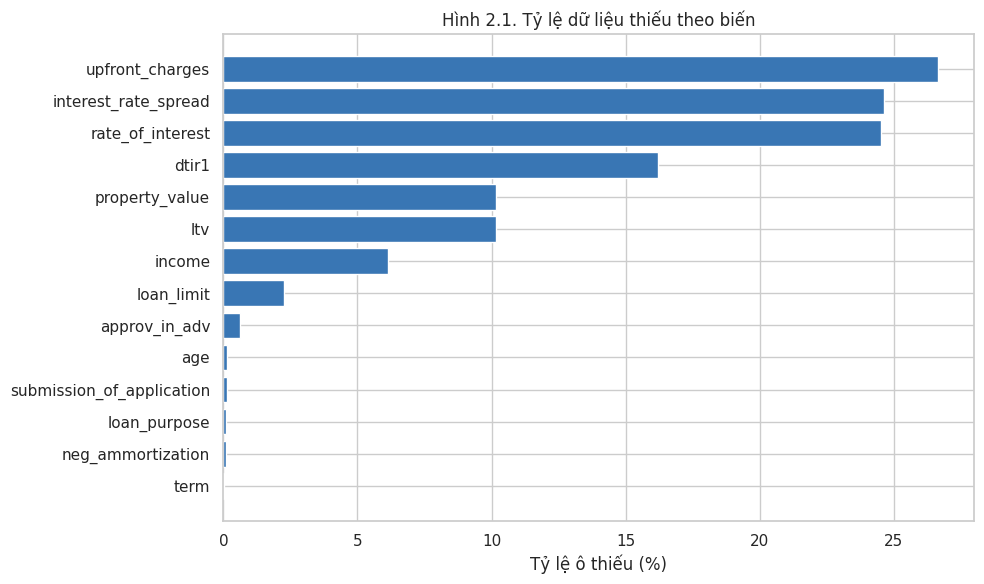

In [195]:
#2.2. Xử lý dữ liệu thiếu (Missing Data Treatment)
#2.2.1. Đánh giá mức độ thiếu dữ liệu
# Kế thừa trực tiếp dữ liệu sau mục 2.1
assert df.shape == (148670, 28)
# Tổng số ô thiếu và số dòng có ít nhất 1 ô thiếu.
missing_counts_before = df.isna().sum()
missing_table = pd.DataFrame({
    "Số ô thiếu": missing_counts_before,
    "Tỷ lệ thiếu (%)": df.isna().mean().mul(100),
})
missing_table = missing_table[missing_table["Số ô thiếu"] > 0].sort_values(
    "Số ô thiếu", ascending=False)

print("Số dòng:", f"{len(df):,}")
print("Số cột có missing:", len(missing_table))
print("Tổng số ô thiếu:", f"{int(missing_counts_before.sum()):,}")
print("Số dòng có ≥ 1 ô thiếu:", f"{int(df.isna().any(axis=1).sum()):,}")
print("Tỷ lệ dòng có ≥ 1 ô thiếu:", f"{100*df.isna().any(axis=1).mean():.2f}%")
display(missing_table.round(3))

# Phân phối số ô thiếu trên một hồ sơ — kiểm tra mức tập trung của missing.
missing_per_row = df.isna().sum(axis=1)
display(missing_per_row.value_counts().sort_index().rename_axis("Ô thiếu / hồ sơ").rename("Số hồ sơ").to_frame())

# Biểu đồ tỷ lệ thiếu từ ít đến nhiều
plt.figure(figsize=(10, 6))
plot_missing = missing_table.sort_values("Tỷ lệ thiếu (%)")
plt.barh(plot_missing.index, plot_missing["Tỷ lệ thiếu (%)"], color="#3976b4")
plt.xlabel("Tỷ lệ ô thiếu (%)")
plt.title("Hình 2.1. Tỷ lệ dữ liệu thiếu theo biến")
plt.tight_layout()

In [196]:
#2.2.2. Phân tích cơ chế thiếu dữ liệu
# Tạo bảng 2x2 giữa tình trạng thiếu và status cho từng cột bị thiếu.
mechanism_rows = []
for col in missing_table.index:
    is_missing = df[col].isna()
    table = pd.crosstab(df["status"], is_missing).reindex(index=[0, 1], columns=[False, True], fill_value=0)

    # Chi-square kiểm định H0: tình trạng thiếu độc lập với status.
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    # Cramér's V cho bảng 2x2 = sqrt(chi-square / n), đo cường độ liên hệ.
    cramers_v = np.sqrt(chi2 / table.values.sum())
    mechanism_rows.append({
        "Biến": col,
        "Thiếu chung (%)": is_missing.mean() * 100,
        "Thiếu | Status=0 (%)": is_missing[df["status"] == 0].mean() * 100,
        "Thiếu | Status=1 (%)": is_missing[df["status"] == 1].mean() * 100,
        "Status=1 | thiếu (%)": df.loc[is_missing, "status"].mean() * 100,
        "Cramér's V": cramers_v,
        "p-value (Chi-square)": p_value
    })
mechanism_table = pd.DataFrame(mechanism_rows).set_index("Biến")
display(mechanism_table.round(4))
print("Tỷ lệ Status=1 toàn bộ:", f"{df['status'].mean()*100:.2f}%")
print("Ghi chú: p-value hiển thị bằng 0 do giới hạn số học = rất nhỏ, không phải xác suất bằng 0 tuyệt đối.")

,Thiếu chung (%),Thiếu | Status=0 (%),Thiếu | Status=1 (%),Status=1 | thiếu (%),Cramér's V,p-value (Chi-square)
Biến,,,,,,
upfront_charges,26.664,2.817,99.582,92.039,0.943,0.000
interest_rate_spread,24.645,0.000,100.000,100.000,1.000,0.000
rate_of_interest,24.510,0.000,99.454,100.000,0.996,0.000
dtir1,16.224,6.972,44.515,67.617,0.439,0.000
property_value,10.155,0.002,41.202,99.987,0.588,0.000
ltv,10.155,0.002,41.202,99.987,0.588,0.000
income,6.155,7.061,3.382,13.541,0.066,0.000
loan_limit,2.249,2.199,2.405,26.346,0.006,0.021
approv_in_adv,0.611,0.595,0.658,26.542,0.004,0.183


Tỷ lệ Status=1 toàn bộ: 24.64%
Ghi chú: p-value hiển thị bằng 0 do giới hạn số học = rất nhỏ, không phải xác suất bằng 0 tuyệt đối.


ltv ↔ property_value: trùng hoàn toàn cờ thiếu: True


property_value thiếu,False,True
ltv thiếu,,
False,133572,0
True,0,15098


age ↔ submission_of_application: trùng hoàn toàn cờ thiếu: True


submission_of_application thiếu,False,True
age thiếu,,
False,148470,0
True,0,200


rate_of_interest ↔ interest_rate_spread: trùng hoàn toàn cờ thiếu: False


interest_rate_spread thiếu,False,True
rate_of_interest thiếu,,
False,112031,200
True,0,36439


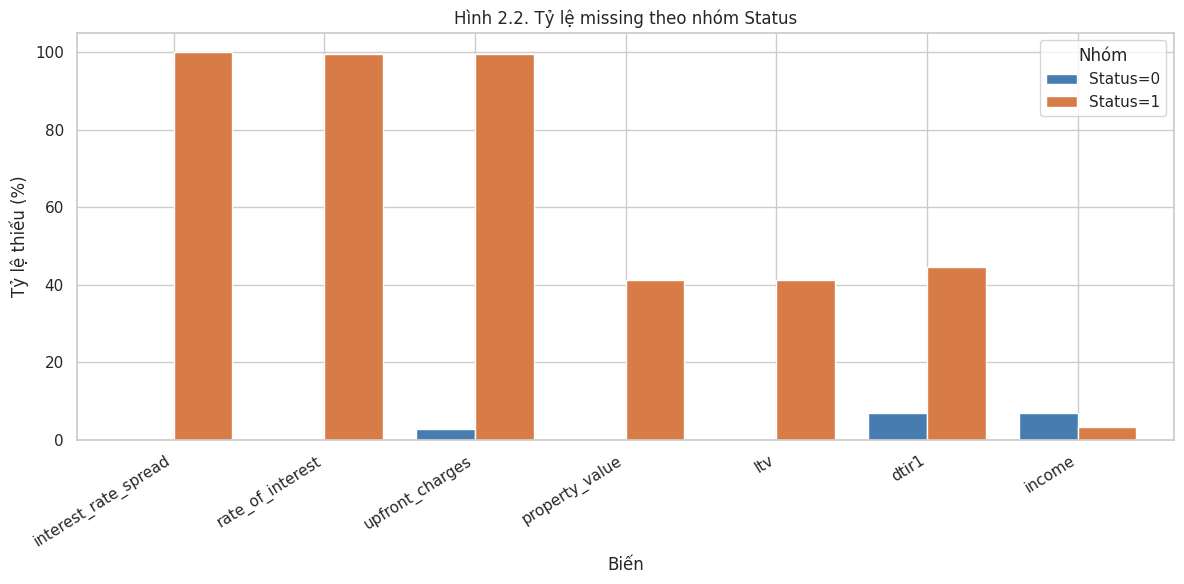

In [197]:
# Trực quan hóa các biến có nhiều dữ liệu thiếu trong hai nhóm status.
compare_cols = ["interest_rate_spread", "rate_of_interest", "upfront_charges",
                "property_value", "ltv", "dtir1", "income"]
compare_missing = mechanism_table.loc[compare_cols,
                                      ["Thiếu | Status=0 (%)", "Thiếu | Status=1 (%)"]]
ax = compare_missing.plot(kind="bar", figsize=(12, 6),
                          color=["#467caf", "#d77c47"], width=0.78)
ax.set_title("Hình 2.2. Tỷ lệ missing theo nhóm Status")
ax.set_xlabel("Biến")
ax.set_ylabel("Tỷ lệ thiếu (%)")
ax.legend(["Status=0", "Status=1"], title="Nhóm")
plt.xticks(rotation=32, ha="right")
plt.tight_layout()

# Kiểm tra các cặp cột thiếu đúng cùng một tập hồ sơ.
shared_missing = [
    ("ltv", "property_value"),
    ("age", "submission_of_application"),
    ("rate_of_interest", "interest_rate_spread"),
]
for col_a, col_b in shared_missing:
    equal_mask = df[col_a].isna().equals(df[col_b].isna())
    print(f"{col_a} ↔ {col_b}: trùng hoàn toàn cờ thiếu: {equal_mask}")
    display(pd.crosstab(df[col_a].isna(), df[col_b].isna(),
                        rownames=[f"{col_a} thiếu"], colnames=[f"{col_b} thiếu"]))

In [198]:
#2.2.3. Lựa chọn phương pháp xử lý
# Lựa chọn dựa trên phương pháp trong bài giảng và đặc điểm mẫu
# Phân tích trong file PDF

In [199]:
# Xem dữ liệu số có lệch phải không: mean, median, skewness của từng cột.
numerical_review = ["loan_amount", "property_value", "income", "ltv",
                    "dtir1", "upfront_charges", "term"]
distribution_table = pd.DataFrame({
    "Mean": df[numerical_review].mean(),
    "Median": df[numerical_review].median(),
    "Skewness": df[numerical_review].skew(),
    "Thiếu (%)": df[numerical_review].isna().mean() * 100,
})
display(distribution_table.round(3))
print("Giá trị mode của term:", df["term"].mode(dropna=True).iloc[0])

,Mean,Median,Skewness,Thiếu (%)
loan_amount,"331,117.744","296,500.000",1.667,0.000
property_value,"497,893.466","418,000.000",4.586,10.155
income,"6,957.339","5,760.000",17.308,6.155
ltv,72.746,75.136,120.615,10.155
dtir1,37.733,39.000,-0.551,16.225
upfront_charges,"3,224.996","2,596.450",1.754,26.664
term,335.137,360.000,-2.175,0.028


Giá trị mode của term: 360.0


In [200]:
df_clean = df.copy()

# Nhóm biến phân loại cần giữ nhãn 'unknown' cho những hồ sơ không ghi nhận.
categorical_impute_cols = ["loan_limit", "approv_in_adv", "loan_purpose",
                           "neg_ammortization", "age", "submission_of_application"]
filled_categorical = int(df_clean[categorical_impute_cols].isna().sum().sum())
for col in categorical_impute_cols:
    df_clean[col] = df_clean[col].fillna("unknown")

# Mode dùng để điền số ít ô thiếu của kỳ hạn vay (term).
term_mode = df_clean["term"].mode(dropna=True).iloc[0]
filled_term = int(df_clean["term"].isna().sum())
df_clean["term"] = df_clean["term"].fillna(term_mode)

# Các biến số này CỐ Ý giữ missing phục vụ phân tích phân phối/so sánh đúng trên dữ liệu quan sát.
keep_nan_cols = ["rate_of_interest", "interest_rate_spread", "upfront_charges",
                 "property_value", "ltv", "dtir1", "income"]
print("Số ô phân loại điền 'unknown':", f"{filled_categorical:,}")
print("Số ô term điền mode:", filled_term, "| mode:", term_mode)
print("7 cột được giữ NaN:", keep_nan_cols)
assert df_clean.shape == df.shape
assert (df_clean["status"].to_numpy() == df["status"].to_numpy()).all()
assert int(df_clean[categorical_impute_cols + ["term"]].isna().sum().sum()) == 0
# Hai nhãn unknown có thể tiết lộ nhãn; chỉ dùng đánh giá chất lượng dữ liệu.
unknown_review = pd.DataFrame([{
    'Biến': col,
    'Số unknown': int(df_clean[col].eq('unknown').sum()),
    'Status=1 trong unknown (%)': 100 * df_clean.loc[df_clean[col].eq('unknown'), 'status'].mean()
} for col in ['age', 'submission_of_application']])
display(unknown_review)
assert (unknown_review['Status=1 trong unknown (%)'] == 100).all()

Số ô phân loại điền 'unknown': 4,907
Số ô term điền mode: 41 | mode: 360.0
7 cột được giữ NaN: ['rate_of_interest', 'interest_rate_spread', 'upfront_charges', 'property_value', 'ltv', 'dtir1', 'income']


,Biến,Số unknown,Status=1 trong unknown (%)
0,age,200,100.000
1,submission_of_application,200,100.000


In [201]:
#2.2.4. So sánh dữ liệu trước và sau xử lý
before_missing = df.isna().sum()
after_missing = df_clean.isna().sum()
comparison_table = pd.DataFrame({
    "Thiếu trước (ô)": before_missing,
    "Thiếu sau (ô)": after_missing,
    "Đã xử lý (ô)": before_missing - after_missing,
    "Tỷ lệ thiếu trước (%)": before_missing / len(df) * 100,
    "Tỷ lệ thiếu sau (%)": after_missing / len(df_clean) * 100
}).loc[missing_table.index]
display(comparison_table.round(3))

# Chỉ số đánh giá chất lượng ở các mốc: gốc, sau cấu trúc, sau xử lý missing.
summary_before_after = pd.DataFrame([
    {"Giai đoạn": "Gốc Chương 1", "Số dòng": len(df_raw), "Số cột": df_raw.shape[1],
     "Số cột thiếu": int(df_raw.isna().any().sum()), "Tổng ô thiếu": int(df_raw.isna().sum().sum()),
     "Dòng có ô thiếu": int(df_raw.isna().any(axis=1).sum())},
    {"Giai đoạn": "Sau 2.1", "Số dòng": len(df), "Số cột": df.shape[1],
     "Số cột thiếu": int(df.isna().any().sum()), "Tổng ô thiếu": int(df.isna().sum().sum()),
     "Dòng có ô thiếu": int(df.isna().any(axis=1).sum())},
    {"Giai đoạn": "Sau 2.2", "Số dòng": len(df_clean), "Số cột": df_clean.shape[1],
     "Số cột thiếu": int(df_clean.isna().any().sum()),
     "Tổng ô thiếu": int(df_clean.isna().sum().sum()),
     "Dòng có ô thiếu": int(df_clean.isna().any(axis=1).sum())},
])
display(summary_before_after)

# Đảm bảo số ô được điền bằng đúng mức giảm missing; không bỏ hồ sơ hoặc đổi biến mục tiêu.
assert int(before_missing.sum() - after_missing.sum()) == filled_categorical + filled_term
assert filled_categorical == 4907 and filled_term == 41
assert int(after_missing.sum()) == 176187
assert len(df_raw) == len(df) == len(df_clean)
for col in keep_nan_cols:
    pd.testing.assert_series_equal(df_clean[col], df[col])
print("Kiểm tra tự động: KHỚP – không mất hồ sơ, không đổi 7 cột số được giữ NaN.")

,Thiếu trước (ô),Thiếu sau (ô),Đã xử lý (ô),Tỷ lệ thiếu trước (%),Tỷ lệ thiếu sau (%)
upfront_charges,39642,39642,0,26.664,26.664
interest_rate_spread,36639,36639,0,24.645,24.645
rate_of_interest,36439,36439,0,24.510,24.510
dtir1,24121,24121,0,16.225,16.225
property_value,15098,15098,0,10.155,10.155
ltv,15098,15098,0,10.155,10.155
income,9150,9150,0,6.155,6.155
loan_limit,3344,0,3344,2.249,0.000
approv_in_adv,908,0,908,0.611,0.000
submission_of_application,200,0,200,0.135,0.000


,Giai đoạn,Số dòng,Số cột,Số cột thiếu,Tổng ô thiếu,Dòng có ô thiếu
0,Gốc Chương 1,148670,34,14,181135,50483
1,Sau 2.1,148670,28,14,181135,50483
2,Sau 2.2,148670,28,7,176187,47337


Kiểm tra tự động: KHỚP – không mất hồ sơ, không đổi 7 cột số được giữ NaN.


,Status,Mean property_value quan sát,Mean nếu điền median toàn bộ,N thiếu
0,0,"505,606.070","505,604.500",2
1,1,"457,786.010","441,393.380",15096


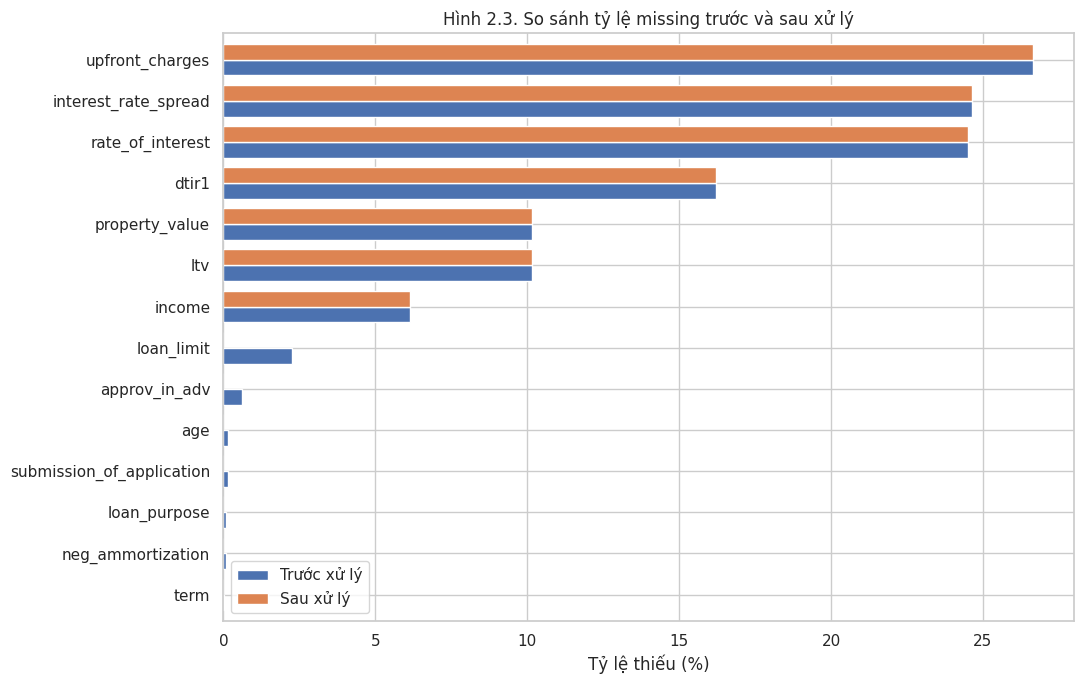

In [202]:
# Biểu đồ so sánh tỷ lệ thiếu trước và sau; 7 biến số còn thiếu được giữ cố ý.
plot_compare = comparison_table[["Tỷ lệ thiếu trước (%)", "Tỷ lệ thiếu sau (%)"]].sort_values("Tỷ lệ thiếu trước (%)")
ax = plot_compare.plot(kind="barh", figsize=(11, 7), width=0.77)
ax.set_xlabel("Tỷ lệ thiếu (%)")
ax.set_title("Hình 2.3. So sánh tỷ lệ missing trước và sau xử lý")
ax.legend(["Trước xử lý", "Sau xử lý"])
plt.tight_layout()


# Minh họa rủi ro gây sai lệch nếu điền median vào property_value trong bộ phân tích.
observed = df["property_value"]
median_filled_demo = observed.fillna(observed.median())  # Chỉ thử nghiệm trên bản Series tách biệt.
median_impact = pd.DataFrame({
    "Status": [0, 1],
    "Mean property_value quan sát": [observed[df.status == s].mean() for s in [0, 1]],
    "Mean nếu điền median toàn bộ": [median_filled_demo[df.status == s].mean() for s in [0, 1]],
    "N thiếu": [int(observed[df.status == s].isna().sum()) for s in [0, 1]]
})
display(median_impact.round(2))

In [203]:
# Bàn giao dữ liệu trong bộ nhớ cho phần 2.3
print("Dữ liệu cuối 2.2 (df_clean):", df_clean.shape)
print("Số ô thiếu còn lại:", int(df_clean.isna().sum().sum()))

Dữ liệu cuối 2.2 (df_clean): (148670, 28)
Số ô thiếu còn lại: 176187


In [204]:
#Phần 2.3 — Phát hiện và xử lý dữ liệu bất thường
df_before = df_clean.copy()
df = df_before.copy()

assert df.shape == (148670, 28), "Kích thước khác đầu ra 2.2."
assert int(df.isna().sum().sum()) == 176187
assert df["status"].isin([0, 1]).all()
print("Đầu vào 2.3 từ df_clean:", df.shape)
print("Ô thiếu còn lại:", int(df.isna().sum().sum()))

Đầu vào 2.3 từ df_clean: (148670, 28)
Ô thiếu còn lại: 176187


In [205]:
#2.3.1. Kiểm tra giá trị không hợp lệ theo nghiệp vụ
# Hàm đếm trường hợp vi phạm, bỏ qua NaN đã được xử lý riêng ở phần 2.2.
def count_invalid(condition, col):
    return int((condition & df[col].notna()).sum())

# Các quy tắc kiểm tra trực tiếp về kiểu đo lường và tính dương/không âm.
checks = {
    "status ngoài {0,1}": count_invalid(~df["status"].isin([0, 1]), "status"),
    "loan_amount <= 0": count_invalid(df["loan_amount"] <= 0, "loan_amount"),
    "property_value <= 0": count_invalid(df["property_value"] <= 0, "property_value"),
    "income < 0": count_invalid(df["income"] < 0, "income"),
    "upfront_charges < 0": count_invalid(df["upfront_charges"] < 0, "upfront_charges"),
    "term <= 0": count_invalid(df["term"] <= 0, "term"),
    "term không nguyên tháng": count_invalid(df["term"].mod(1).ne(0), "term"),
    "rate_of_interest ngoài [0,100]": count_invalid(~df["rate_of_interest"].between(0, 100), "rate_of_interest"),
    "dtir1 ngoài [0,100]": count_invalid(~df["dtir1"].between(0, 100), "dtir1"),
    "ltv <= 0": count_invalid(df["ltv"] <= 0, "ltv"),
    "credit_score < 0": count_invalid(df["credit_score"] < 0, "credit_score"),
}

# Kiểm tra bổ sung các giá trị vô hạn ở những cột định lượng.
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
checks["Giá trị số vô hạn +/-inf"] = int(np.isinf(df[num_cols].to_numpy(dtype=float)).sum())

# Tạo và hiển thị bảng kiểm tra điều kiện nghiệp vụ.
invalid_table = pd.DataFrame({"Điều kiện kiểm tra": list(checks), "Số vi phạm": list(checks.values())})
display(invalid_table)
print("Tổng vi phạm các quy tắc kiểm tra:", int(invalid_table["Số vi phạm"].sum()))

,Điều kiện kiểm tra,Số vi phạm
0,"status ngoài {0,1}",0
1,loan_amount <= 0,0
2,property_value <= 0,0
3,income < 0,0
4,upfront_charges < 0,0
5,term <= 0,0
6,term không nguyên tháng,0
7,"rate_of_interest ngoài [0,100]",0
8,"dtir1 ngoài [0,100]",0
9,ltv <= 0,0


Tổng vi phạm các quy tắc kiểm tra: 0


In [206]:
# Tạo những cảnh báo dữ liệu có thể là ngoại lệ nghiệp vụ, nhưng CHƯA chứng minh là lỗi.
warning_masks = {
    "LTV > 100%": df["ltv"].gt(100),
    "LTV > 1.000%": df["ltv"].gt(1000),
    "Thu nhập bằng 0": df["income"].eq(0),
    "Lãi suất danh nghĩa bằng 0": df["rate_of_interest"].eq(0),
    "Kỳ hạn không chia hết cho 12": df["term"].mod(12).ne(0),
}
warning_table = pd.DataFrame({"Điểm cần kiểm tra": list(warning_masks),
                              "Số hồ sơ": [int(m.sum()) for m in warning_masks.values()]})
print("Các trường hợp cần xác minh thêm theo nghiệp vụ:")
display(warning_table)
print("Các kỳ hạn lẻ tháng:", df.loc[warning_masks["Kỳ hạn không chia hết cho 12"], "term"].value_counts().to_dict())
print("6 hồ sơ LTV > 1.000% (giữ nguyên, KHÔNG tự sửa):")
display(df.loc[warning_masks["LTV > 1.000%"],
               ["loan_amount", "property_value", "ltv", "status"]])

Các trường hợp cần xác minh thêm theo nghiệp vụ:


,Điểm cần kiểm tra,Số hồ sơ
0,LTV > 100%,1799
1,LTV > 1.000%,6
2,Thu nhập bằng 0,1260
3,Lãi suất danh nghĩa bằng 0,1
4,Kỳ hạn không chia hết cho 12,3


Các kỳ hạn lẻ tháng: {165.0: 1, 280.0: 1, 322.0: 1}
6 hồ sơ LTV > 1.000% (giữ nguyên, KHÔNG tự sửa):


,loan_amount,property_value,ltv,status
16951,626500,"8,000.000","7,831.250",0
46287,236500,"8,000.000","2,956.250",1
47807,416500,"8,000.000","5,206.250",0
55286,536500,"8,000.000","6,706.250",0
65238,376500,"8,000.000","4,706.250",0
123343,186500,"8,000.000","2,331.250",0


In [207]:
#2.3.2. Phát hiện ngoại lai bằng IQR
# Chọn các biến số phù hợp để dò ngoại lai; loại status và term khỏi phép tính IQR.
iqr_cols = ["loan_amount", "rate_of_interest", "interest_rate_spread",
            "upfront_charges", "property_value", "income",
            "credit_score", "ltv", "dtir1"]

# Lưu cờ ngoại lai cho từng hồ sơ và thống kê theo mỗi biến.
outlier_flags = pd.DataFrame(False, index=df.index, columns=iqr_cols)
rows = []
for col in iqr_cols:
    # Pandas bỏ qua NaN khi tính phân vị và khi so sánh điều kiện.
    series = df[col]
    q1 = float(series.quantile(0.25))
    q3 = float(series.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flag = (series < lower) | (series > upper)
    outlier_flags[col] = flag.fillna(False)
    n_valid = int(series.notna().sum())
    rows.append({"Biến": col, "N có dữ liệu": n_valid,
                 "Q1": q1, "Q3": q3, "IQR": iqr,
                 "Ngưỡng dưới": lower, "Ngưỡng trên": upper,
                 "Ngoại lai thấp": int((series < lower).sum()),
                 "Ngoại lai cao": int((series > upper).sum()),
                 "Tổng ngoại lai": int(flag.sum()),
                 "Tỷ lệ/giá trị hợp lệ (%)": 100 * flag.sum() / n_valid})

iqr_table = pd.DataFrame(rows)
print("Bảng tính các khoảng IQR (không bao gồm biến status/term):")
display(iqr_table.round(3))
print("Số dòng có ít nhất một ngoại lai IQR:", int(outlier_flags.any(axis=1).sum()))
print("Tổng lượt gắn cờ IQR (có thể trùng nhau trên cùng hồ sơ):", int(outlier_flags.sum().sum()))


Bảng tính các khoảng IQR (không bao gồm biến status/term):


,Biến,N có dữ liệu,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Ngoại lai thấp,Ngoại lai cao,Tổng ngoại lai,Tỷ lệ/giá trị hợp lệ (%)
0,loan_amount,148670,"196,500.000","436,500.000","240,000.000","-163,500.000","796,500.000",0,1895,1895,1.275
1,rate_of_interest,112231,3.625,4.375,0.750,2.500,5.500,10,846,856,0.763
2,interest_rate_spread,112031,0.076,0.775,0.699,-0.973,1.824,31,414,445,0.397
3,upfront_charges,109028,581.490,"4,812.500","4,231.010","-5,765.025","11,159.015",0,2880,2880,2.642
4,property_value,133572,"268,000.000","628,000.000","360,000.000","-272,000.000","1,168,000.000",0,5266,5266,3.942
5,income,139520,"3,720.000","8,520.000","4,800.000","-3,480.000","15,720.000",0,6546,6546,4.692
6,credit_score,148670,599.000,800.000,201.000,297.500,"1,101.500",0,0,0,0.000
7,ltv,133572,60.475,86.184,25.709,21.911,124.748,1762,120,1882,1.409
8,dtir1,124549,31.000,45.000,14.000,10.000,66.000,2013,0,2013,1.616


Số dòng có ít nhất một ngoại lai IQR: 16400
Tổng lượt gắn cờ IQR (có thể trùng nhau trên cùng hồ sơ): 21783


In [208]:
# Phân tích riêng thời hạn vay bằng tần suất, tránh việc IQR = 0 làm sai kết luận.
term_q1 = float(df["term"].quantile(0.25))
term_q3 = float(df["term"].quantile(0.75))
term_diff_360 = int(df["term"].ne(360).sum())
print(f"term: Q1={term_q1:g}, Q3={term_q3:g}, IQR={term_q3 - term_q1:g}.")
print(f"Có {term_diff_360:,} khoản vay với term khác 360 tháng; không kết luận những hồ sơ này là lỗi.")
print("Các kỳ hạn phổ biến:")
display(df["term"].value_counts().head(8).rename("Số hồ sơ").to_frame())


term: Q1=360, Q3=360, IQR=0.
Có 26,944 khoản vay với term khác 360 tháng; không kết luận những hồ sơ này là lỗi.
Các kỳ hạn phổ biến:


,Số hồ sơ
term,
360.000,121726
180.000,12981
240.000,5859
300.000,2822
324.000,2766
120.000,510
144.000,263
348.000,260


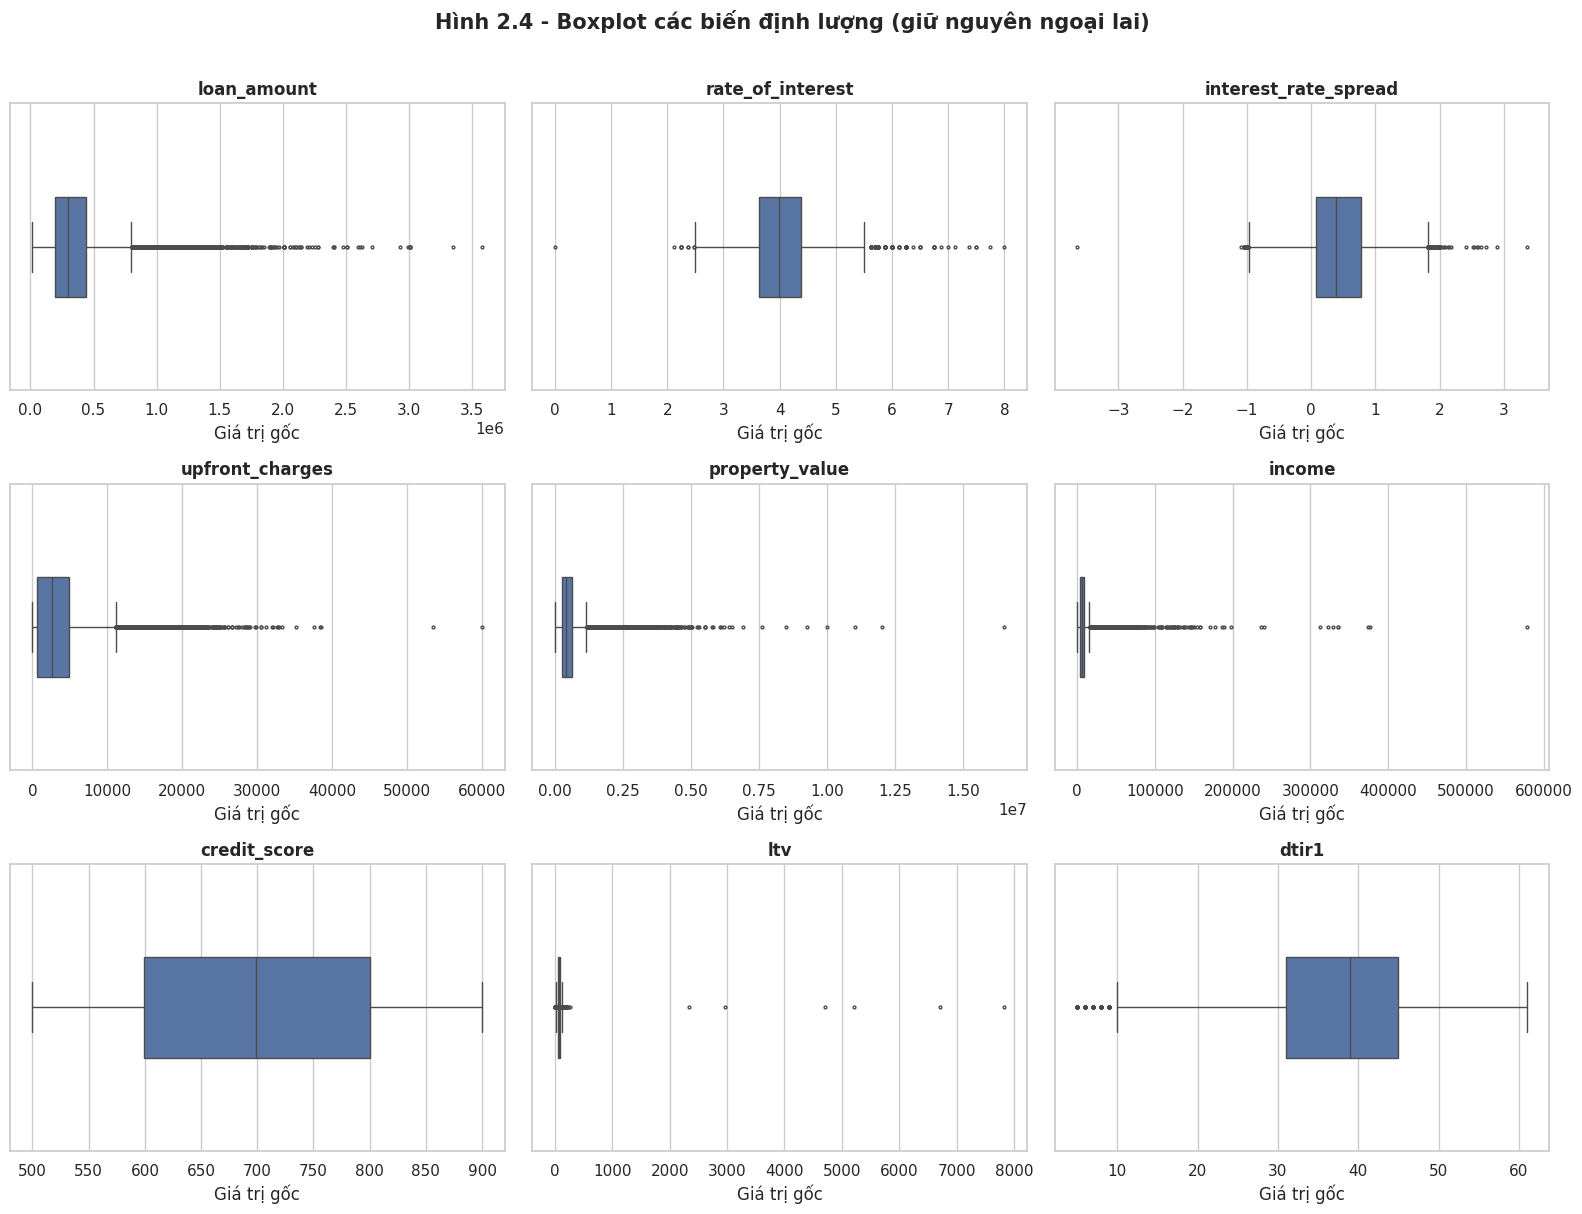

In [209]:
#2.3.3. Trực quan hóa ngoại lai
# Hình 2.4: Vẽ boxplot 9 biến, chia theo từng ô vì đơn vị đo khác nhau.
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, iqr_cols):
    sns.boxplot(x=df[col].dropna(), ax=ax, fliersize=2,
                linewidth=1, width=.35)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_xlabel("Giá trị gốc")
fig.suptitle("Hình 2.4 - Boxplot các biến định lượng (giữ nguyên ngoại lai)",
             fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()


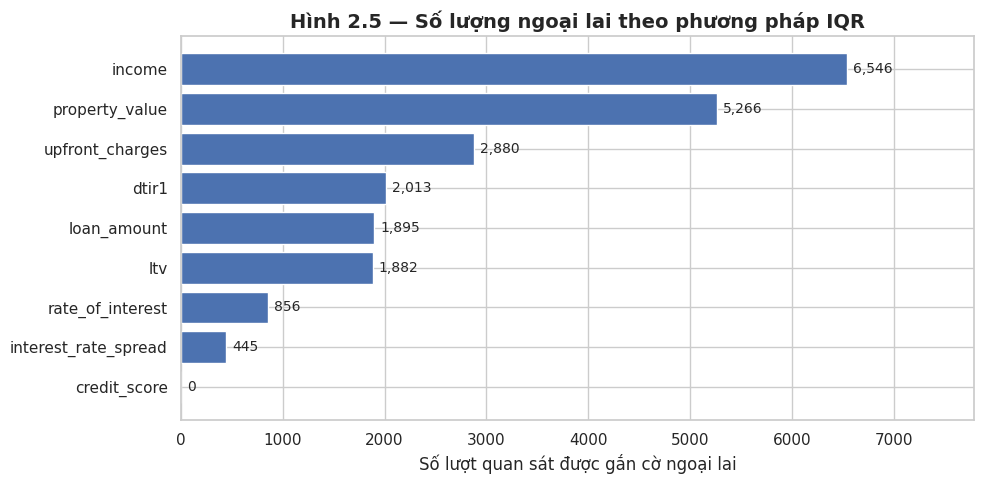

In [210]:
# Hình 2.5: So sánh số lượng ngoại lai IQR trên cùng một đồ thị.
fig, ax = plt.subplots(figsize=(10, 5))
plot_counts = iqr_table.sort_values("Tổng ngoại lai", ascending=True)
ax.barh(plot_counts["Biến"], plot_counts["Tổng ngoại lai"])
for i, v in enumerate(plot_counts["Tổng ngoại lai"]):
    ax.text(v + 60, i, f"{v:,}", va="center", fontsize=10)
ax.set_xlim(0, max(plot_counts["Tổng ngoại lai"]) * 1.19)
ax.set_xlabel("Số lượt quan sát được gắn cờ ngoại lai")
ax.set_title("Hình 2.5 — Số lượng ngoại lai theo phương pháp IQR", fontsize=14, fontweight="bold")
fig.tight_layout()


Số LTV cực trị >1.000%: 6


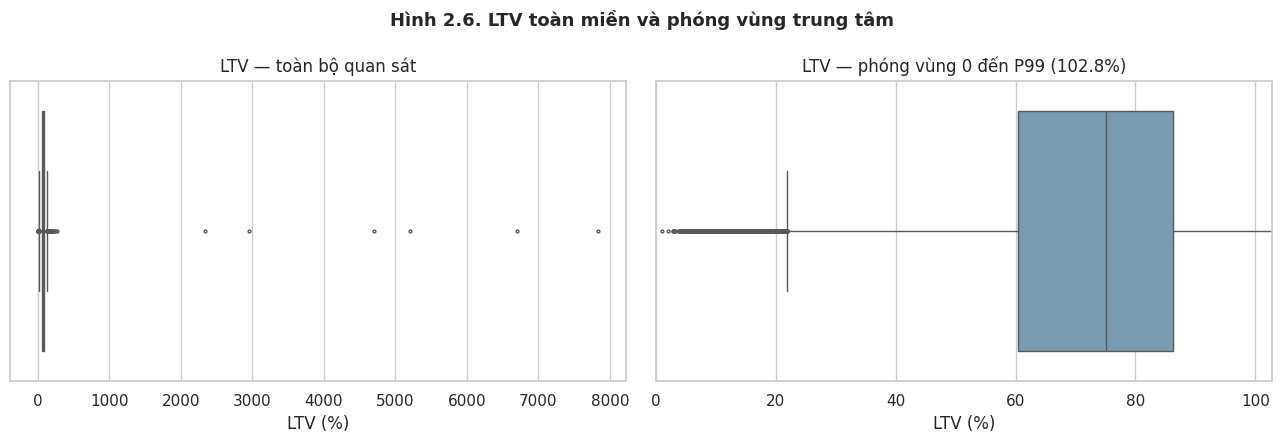

In [211]:
# Hình 2.6: so sánh toàn bộ LTV với vùng phóng đến P99
ltv_nonnull = df['ltv'].dropna()
ltv_p99 = float(ltv_nonnull.quantile(.99))
print('Số LTV cực trị >1.000%:', int(ltv_nonnull.gt(1000).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=ltv_nonnull, ax=axes[0], color='#6E9DBB', fliersize=2)
axes[0].set_title('LTV — toàn bộ quan sát')
axes[0].set_xlabel('LTV (%)')

sns.boxplot(x=ltv_nonnull, ax=axes[1], color='#6E9DBB', fliersize=2)
axes[1].set_xlim(0, ltv_p99)
axes[1].set_title(f'LTV — phóng vùng 0 đến P99 ({ltv_p99:.1f}%)')
axes[1].set_xlabel('LTV (%)')

fig.suptitle('Hình 2.6. LTV toàn miền và phóng vùng trung tâm', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [212]:
#2.3.4. Quyết định xử lý ngoại lai
df_after = df.copy()

# Tạo danh sách hồ sơ cần rà soát
audit_mask = outlier_flags.any(axis=1) | pd.concat(warning_masks, axis=1).any(axis=1)
audit = pd.DataFrame(index=df.index)
audit["dong_trong_file_2_2"] = df.index + 2
audit["status"] = df["status"]
for col in iqr_cols:
    audit[f"iqr_{col}"] = outlier_flags[col].astype(int)
for label, flag in warning_masks.items():
    audit["canh_bao_" + {"LTV > 100%":"ltv_gt_100", "LTV > 1.000%":"ltv_gt_1000",
                "Thu nhập bằng 0":"income_eq_0", "Lãi suất danh nghĩa bằng 0":"rate_eq_0",
                "Kỳ hạn không chia hết cho 12":"term_not_multiple_12"}[label]] = flag.astype(int)

# Ghi chỉ những dòng có ít nhất một cờ để dễ kiểm tra nguồn.
audit_flagged = audit.loc[audit_mask].copy()

# Kiểm chứng: không xóa dòng, không đổi cột, không sửa dữ liệu đã xử lý ở 2.2.
pd.testing.assert_frame_equal(df_before, df_after, check_dtype=True, check_exact=True)
assert df_after.shape == (148670, 28)
assert int(df_after.isna().sum().sum()) == 176187
assert len(audit_flagged) == int(audit_mask.sum())

# In bảng so sánh trước và sau để minh bạch toàn bộ lựa chọn.
compare = pd.DataFrame({
    "Chỉ tiêu": ["Số hồ sơ", "Số biến", "Số ô thiếu", "Số hồ sơ có ngoại lai IQR",
                 "Số hồ sơ bị loại", "Số giá trị bị sửa"],
    "Trước mục 2.3": [len(df_before), df_before.shape[1], int(df_before.isna().sum().sum()),
                       int(outlier_flags.any(axis=1).sum()), 0, 0],
    "Sau mục 2.3": [len(df_after), df_after.shape[1], int(df_after.isna().sum().sum()),
                     int(outlier_flags.any(axis=1).sum()), 0, 0],
})
display(compare)
print("Số hồ sơ trong danh sách kiểm tra (cờ IQR HOẶC cảnh báo nghiệp vụ):", len(audit_flagged))



,Chỉ tiêu,Trước mục 2.3,Sau mục 2.3
0,Số hồ sơ,148670,148670
1,Số biến,28,28
2,Số ô thiếu,176187,176187
3,Số hồ sơ có ngoại lai IQR,16400,16400
4,Số hồ sơ bị loại,0,0
5,Số giá trị bị sửa,0,0


Số hồ sơ trong danh sách kiểm tra (cờ IQR HOẶC cảnh báo nghiệp vụ): 19130


In [213]:
#2.4. Kiểm tra tính nhất quán giữa các biến
df_input = df_after.copy()
df = df_input.copy()

assert df.shape == (148670, 28)
assert int(df.isna().sum().sum()) == 176187
assert set(df["status"].unique()) == {0, 1}
print("Đầu vào 2.4 từ df_after:", df.shape)
print("Số hồ sơ status=1:", int(df["status"].eq(1).sum()))

Đầu vào 2.4 từ df_after: (148670, 28)
Số hồ sơ status=1: 36639


In [214]:
#2.4.1. Kiểm tra tính hợp lý của LTV
# Chỉ so sánh công thức ở những hồ sơ có đủ 3 biến và tài sản thế chấp dương.
valid = df[['loan_amount', 'property_value', 'ltv']].notna().all(axis=1) & df['property_value'].gt(0)
ltv_calculated = df.loc[valid, 'loan_amount'] / df.loc[valid, 'property_value'] * 100
ltv_error = (df.loc[valid, 'ltv'] - ltv_calculated).abs()

# Xác định số dòng sai khác ngoài sai số làm tròn máy tính.
tolerance = 1e-6
ltv_summary = pd.DataFrame([
    {'Chỉ tiêu': 'Số hồ sơ có đủ ba biến để kiểm tra', 'Giá trị': int(valid.sum())},
    {'Chỉ tiêu': 'LTV lệch công thức > 1e-6', 'Giá trị': int(ltv_error.gt(tolerance).sum())},
    {'Chỉ tiêu': 'Sai số tuyệt đối lớn nhất', 'Giá trị': float(ltv_error.max())},
    {'Chỉ tiêu': 'Cả property_value và ltv đều thiếu', 'Giá trị': int((df['property_value'].isna() & df['ltv'].isna()).sum())},
    {'Chỉ tiêu': 'Chỉ một trong hai biến thiếu', 'Giá trị': int((df['property_value'].isna() ^ df['ltv'].isna()).sum())},
    {'Chỉ tiêu': 'LTV > 100%', 'Giá trị': int(df['ltv'].gt(100).sum())},
    {'Chỉ tiêu': 'LTV > 1.000%', 'Giá trị': int(df['ltv'].gt(1000).sum())},
])
print('Bảng 2.4.1 — Đối chiếu LTV:')
display(ltv_summary)

# Sáu hồ sơ cực trị chỉ chuyển sang danh sách kiểm tra, không tự sửa hoặc xóa.
ltv_extreme = df.loc[df['ltv'].gt(1000),
    ['loan_amount', 'property_value', 'ltv', 'income', 'status']].copy()
ltv_extreme.insert(0, 'dong_du_lieu', ltv_extreme.index + 2)
print('Sáu dòng LTV > 1000%:')
display(ltv_extreme)
assert int(ltv_error.gt(tolerance).sum()) == 0
assert int((df['property_value'].isna() ^ df['ltv'].isna()).sum()) == 0

Bảng 2.4.1 — Đối chiếu LTV:


,Chỉ tiêu,Giá trị
0,Số hồ sơ có đủ ba biến để kiểm tra,"133,572.000"
1,LTV lệch công thức > 1e-6,0.000
2,Sai số tuyệt đối lớn nhất,0.000
3,Cả property_value và ltv đều thiếu,"15,098.000"
4,Chỉ một trong hai biến thiếu,0.000
5,LTV > 100%,"1,799.000"
6,LTV > 1.000%,6.000


Sáu dòng LTV > 1000%:


,dong_du_lieu,loan_amount,property_value,ltv,income,status
16951,16953,626500,"8,000.000","7,831.250",NaN,0
46287,46289,236500,"8,000.000","2,956.250",NaN,1
47807,47809,416500,"8,000.000","5,206.250",NaN,0
55286,55288,536500,"8,000.000","6,706.250",NaN,0
65238,65240,376500,"8,000.000","4,706.250",NaN,0
123343,123345,186500,"8,000.000","2,331.250",NaN,0


In [215]:
#2.4.2. Kiểm tra sự đồng nhất về thời điểm ghi nhận
# Bộ dữ liệu chỉ có cùng năm 2019 và không có trường ngày để đối chiếu trình tự.
assert df_raw['year'].nunique(dropna=False) == 1
print('Năm duy nhất:', df_raw['year'].iloc[0])
print('Không có mốc ngày tiếp nhận, giải ngân và phát sinh status: chưa xác minh được thứ tự thời gian.')

Năm duy nhất: 2019
Không có mốc ngày tiếp nhận, giải ngân và phát sinh status: chưa xác minh được thứ tự thời gian.


In [216]:
#2.4.3. Kiểm tra Data Leakage
# Đối chiếu xác suất status=1 trong nhóm thiếu với mức nền toàn mẫu.
missing_cols = ['interest_rate_spread', 'rate_of_interest', 'upfront_charges',
                'property_value', 'ltv', 'dtir1', 'income']
baseline = 100 * df['status'].mean()
leakage_rows = []
for col in missing_cols:
    missing = df[col].isna()
    pct0 = 100 * missing[df['status'].eq(0)].mean()
    pct1 = 100 * missing[df['status'].eq(1)].mean()
    p_default_missing = 100 * df.loc[missing, 'status'].mean()
    leakage_rows.append({
        'Biến': col,
        'Thiếu khi status=0 (%)': pct0,
        'Thiếu khi status=1 (%)': pct1,
        'P(status=1 | thiếu) (%)': p_default_missing,
        'Mức nền status=1 (%)': baseline,
        'Cramér V': mechanism_table.loc[col, "Cramér's V"]
    })
leakage_table = pd.DataFrame(leakage_rows)
print('Bảng 2.4.3 — Liên hệ giữa thiếu dữ liệu và status:')
display(leakage_table.round(3))

# Kiểm tra mối liên hệ hoàn hảo ở cột interest_rate_spread.
spread_missing = df['interest_rate_spread'].isna()
display(pd.crosstab(df['status'], spread_missing))
assert spread_missing.astype(int).eq(df['status']).all()

# Hai nhãn unknown: 200 hồ sơ và tất cả status=1, KHÔNG dùng nhóm này để giải thích EDA.
for col in ['age', 'submission_of_application']:
    mask = df[col].eq('unknown')
    print(col, ':', int(mask.sum()), 'unknown; P(status=1 | unknown) =',
          round(100 * df.loc[mask, 'status'].mean(), 2), '%')

Bảng 2.4.3 — Liên hệ giữa thiếu dữ liệu và status:


,Biến,Thiếu khi status=0 (%),Thiếu khi status=1 (%),P(status=1 | thiếu) (%),Mức nền status=1 (%),Cramér V
0,interest_rate_spread,0.000,100.000,100.000,24.645,1.000
1,rate_of_interest,0.000,99.454,100.000,24.645,0.996
2,upfront_charges,2.817,99.582,92.039,24.645,0.943
3,property_value,0.002,41.202,99.987,24.645,0.588
4,ltv,0.002,41.202,99.987,24.645,0.588
5,dtir1,6.972,44.515,67.617,24.645,0.439
6,income,7.061,3.382,13.541,24.645,0.066


interest_rate_spread,False,True
status,,
0,112031,0
1,0,36639


age : 200 unknown; P(status=1 | unknown) = 100.0 %
submission_of_application : 200 unknown; P(status=1 | unknown) = 100.0 %


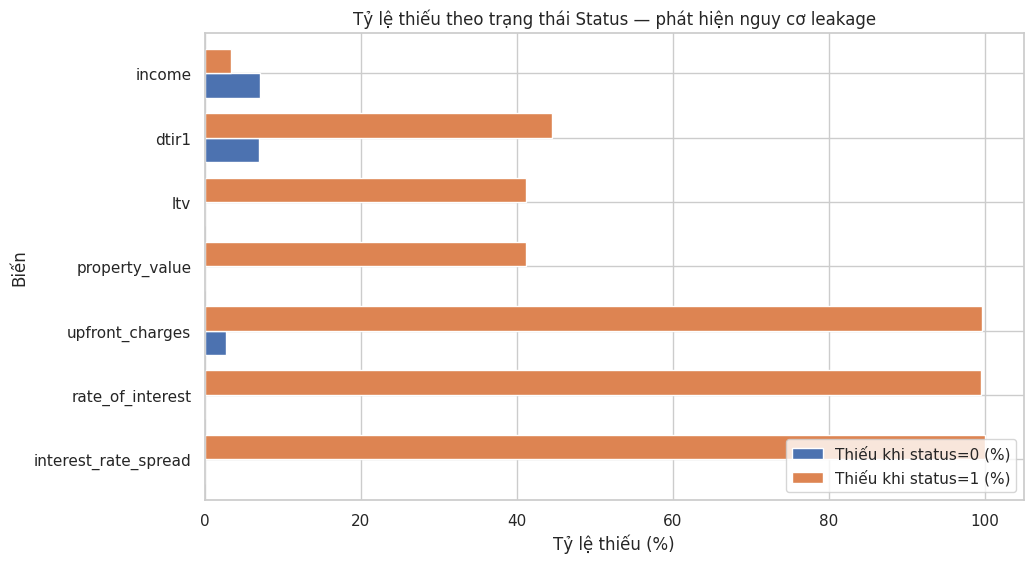

In [217]:
# Vẽ tỷ lệ thiếu của các biến trọng điểm theo status
plot_cols = ['interest_rate_spread', 'rate_of_interest', 'upfront_charges',
             'property_value', 'ltv', 'dtir1', 'income']
chart_data = (leakage_table.set_index('Biến')
              .loc[plot_cols, ['Thiếu khi status=0 (%)', 'Thiếu khi status=1 (%)']])
ax = chart_data.plot(kind='barh', figsize=(10.5, 5.8), width=0.76)
ax.set_xlabel('Tỷ lệ thiếu (%)')
ax.set_ylabel('Biến')
ax.set_xlim(0, 105)
ax.set_title('Tỷ lệ thiếu theo trạng thái Status — phát hiện nguy cơ leakage')
ax.legend(loc='lower right')
plt.tight_layout()


In [218]:
#2.5. Feature Engineering có chọn lọc
df_fe = df.copy()

# Tránh chia cho 0; giữ NaN nếu income thiếu hoặc income=0 (không tự đoán thu nhập).
positive_income = df_fe['income'].gt(0)
df_fe['loan_income_ratio'] = (df_fe['loan_amount'] /
                              df_fe['income'].where(positive_income))

# Dùng log loan_amount; income=0 không có log xác định, giữ NaN nhất quán với loan_income_ratio.
df_fe['log_loan_amount'] = np.log1p(df_fe['loan_amount'])
df_fe['log_income'] = np.log(df_fe['income'].where(df_fe['income'] > 0))

# Cờ kỳ hạn 360 tháng, có tính đến 41 giá trị term đã được điền mode ở mục 2.2.
df_fe['term_360_flag'] = df_fe['term'].eq(360).astype('int8')

# Các khoảng điểm cố định để trình bày EDA, không dùng ngưỡng này làm chuẩn đánh giá tín dụng.
score_bins = [499, 599, 699, 799, 900]
score_labels = ['500–599', '600–699', '700–799', '800–900']
df_fe['credit_score_band'] = pd.cut(df_fe['credit_score'], bins=score_bins,
                                     labels=score_labels, include_lowest=True)

# Tóm tắt dữ liệu tạo mới.
features = ['loan_income_ratio', 'log_loan_amount', 'log_income',
            'term_360_flag', 'credit_score_band']
summary_features = pd.DataFrame({
    'Biến tạo mới': features,
    'Số quan sát không thiếu': [int(df_fe[c].notna().sum()) for c in features],
    'Số giá trị thiếu': [int(df_fe[c].isna().sum()) for c in features],
})
print('Số biến mới:', len(features), '| Kích thước sau tạo đặc trưng:', df_fe.shape)
display(summary_features)
print('Đặc điểm tỷ lệ vay / thu nhập (chỉ tính income dương):')
display(df_fe['loan_income_ratio'].describe(percentiles=[.25, .5, .75, .95, .99]).round(3))
print('Phân phối nhóm điểm tín dụng:')
display(df_fe['credit_score_band'].value_counts(sort=False).to_frame('Số hồ sơ'))
print('Số kỳ hạn 360 tháng:', int(df_fe['term_360_flag'].sum()))
print('Độ lệch (skewness) trước/sau log:')
display(pd.DataFrame({'Biến': ['loan_amount → log_loan_amount', 'income → log_income'],
                      'Skew gốc': [df['loan_amount'].skew(), df['income'].skew()],
                      'Skew sau log': [df_fe['log_loan_amount'].skew(), df_fe['log_income'].skew()]}).round(3))


Số biến mới: 5 | Kích thước sau tạo đặc trưng: (148670, 33)


,Biến tạo mới,Số quan sát không thiếu,Số giá trị thiếu
0,loan_income_ratio,138260,10410
1,log_loan_amount,148670,0
2,log_income,138260,10410
3,term_360_flag,148670,0
4,credit_score_band,148670,0


Đặc điểm tỷ lệ vay / thu nhập (chỉ tính income dương):


,loan_income_ratio
count,"138,260.000"
mean,56.542
std,95.487
min,0.599
25%,37.216
50%,52.292
75%,69.845
95%,97.817
99%,127.632
max,"25,275.000"


Phân phối nhóm điểm tín dụng:


,Số hồ sơ
credit_score_band,
500–599,37190
600–699,37200
700–799,36811
800–900,37469


Số kỳ hạn 360 tháng: 121726
Độ lệch (skewness) trước/sau log:


,Biến,Skew gốc,Skew sau log
0,loan_amount → log_loan_amount,1.667,-0.397
1,income → log_income,17.308,0.006


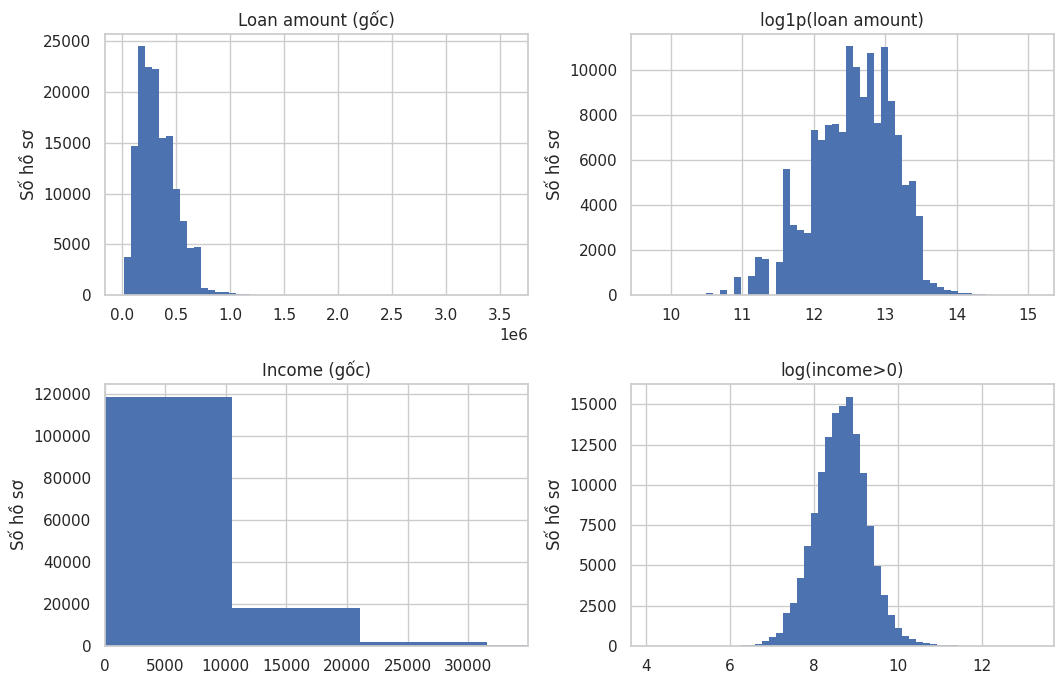

In [219]:
# Biểu đồ minh họa sự thay đổi hình dạng phân phối sau phép biến đổi log.
fig, axs = plt.subplots(2, 2, figsize=(10.8, 7))
for ax, col, ttl in [(axs[0,0], 'loan_amount', 'Loan amount (gốc)'),
                     (axs[0,1], 'log_loan_amount', 'log1p(loan amount)'),
                     (axs[1,0], 'income', 'Income (gốc)'),
                     (axs[1,1], 'log_income', 'log(income>0)')]:
    vals = df_fe[col].dropna()
    ax.hist(vals, bins=55, edgecolor='none')
    if col == 'income':
        ax.set_xlim(0, vals.quantile(.995))  # Trục hiển thị phóng to, dữ liệu không bị xóa.
    ax.set_title(ttl)
    ax.set_ylabel('Số hồ sơ')
plt.tight_layout()

In [220]:
# Đối chiếu 28 biến cũ với bản sao ở đầu mục 2.4; không thay đổi giá trị gốc.
pd.testing.assert_frame_equal(df_fe[df.columns], df_input, check_exact=True)
assert df_fe.shape == (148670, 33)
assert not np.isinf(df_fe[['loan_income_ratio', 'log_loan_amount', 'log_income']].to_numpy()).any()
assert int(df_fe['loan_income_ratio'].isna().sum()) == int(df['income'].isna().sum() + df['income'].eq(0).sum())
assert df_fe['credit_score_band'].notna().all()

compare_final = pd.DataFrame({
    'Chỉ tiêu': ['Số hồ sơ', 'Số biến', 'Thiếu ở 28 biến cũ',
                'Thiếu phát sinh trong 5 biến mới', 'Tổng ô thiếu trên toàn bảng'],
    'Đầu vào sau 2.3': [len(df_input), df_input.shape[1], int(df_input.isna().sum().sum()),
                        0, int(df_input.isna().sum().sum())],
    'Đầu ra sau 2.5': [len(df_fe), df_fe.shape[1],
                      int(df_fe[df.columns].isna().sum().sum()),
                      int(df_fe[features].isna().sum().sum()),
                      int(df_fe.isna().sum().sum())]
})
display(compare_final)
print('Dữ liệu sau mục 2.5 nằm trong biến df_fe:', df_fe.shape)

,Chỉ tiêu,Đầu vào sau 2.3,Đầu ra sau 2.5
0,Số hồ sơ,148670,148670
1,Số biến,28,33
2,Thiếu ở 28 biến cũ,176187,176187
3,Thiếu phát sinh trong 5 biến mới,0,20820
4,Tổng ô thiếu trên toàn bảng,176187,197007


Dữ liệu sau mục 2.5 nằm trong biến df_fe: (148670, 33)


In [221]:
#2.6. Mã hóa và chuẩn hóa dữ liệu
#2.6.1. Xác định nhu cầu mã hóa
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler

df_final = df_fe.copy()
assert df_final.shape == (148670, 33)
assert df_final['status'].notna().all() and set(df_final['status'].unique()) == {0, 1}
print('Đầu vào mục 2.6', df_final.shape)
print('Các biến phân loại:', len(df_final.select_dtypes(include=['object', 'string', 'category']).columns))
print('Tổng ô thiếu:', int(df_final.isna().sum().sum()))

Đầu vào mục 2.6 (148670, 33)
Các biến phân loại: 18
Tổng ô thiếu: 197007


In [222]:
# Chỉ loại biến ở nhánh phục vụ xây dựng mô hình; vẫn lưu chúng trong dữ liệu EDA.
# Loại các biến có nguy cơ hé lộ nhãn/không xác định thời điểm ghi nhận.
leakage_excluded = ['interest_rate_spread','rate_of_interest','upfront_charges',
                    'property_value','ltv','dtir1',
                    'age','submission_of_application','credit_type']

# Giữ biến log thay tiền gốc và giữ credit_score thay nhóm điểm trùng lặp.
redundancy_excluded = ['loan_amount','income','credit_score_band']
excluded = ['status'] + leakage_excluded + redundancy_excluded
feature_cols = [col for col in df_final.columns if col not in excluded]

# Phân loại biến chữ cần One-Hot; không mã hóa status và không gán thứ tự tùy tiện cho nhãn chữ.
all_categorical = df_final.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
cat_cols = [col for col in feature_cols if col in all_categorical]
cat_summary = pd.DataFrame({
    'Biến phân loại': all_categorical,
    'Số nhãn': [df_final[col].nunique(dropna=True) for col in all_categorical],
    'Phương pháp': ['Không đưa vào mô hình (đã có credit_score)' if col=='credit_score_band'
                   else ('Loại khỏi mô hình do unknown ↔ status' if col in ['age','submission_of_application','credit_type']
                   else 'One-Hot Encoding') for col in all_categorical]
})
assert len(all_categorical)==18 and len(cat_cols)==14
print('Tổng biến dạng chữ:',len(all_categorical), '| One-Hot trong mô hình:',len(cat_cols))
print('Số biến đầu vào dự kiến:',len(feature_cols))
display(cat_summary)

Tổng biến dạng chữ: 18 | One-Hot trong mô hình: 14
Số biến đầu vào dự kiến: 20


,Biến phân loại,Số nhãn,Phương pháp
0,loan_limit,3,One-Hot Encoding
1,gender,4,One-Hot Encoding
2,approv_in_adv,3,One-Hot Encoding
3,loan_type,3,One-Hot Encoding
4,loan_purpose,5,One-Hot Encoding
5,credit_worthiness,2,One-Hot Encoding
6,open_credit,2,One-Hot Encoding
7,neg_ammortization,3,One-Hot Encoding
8,interest_only,2,One-Hot Encoding
9,lump_sum_payment,2,One-Hot Encoding


In [223]:
#2.6.2. Xác định nhu cầu Scaling
# Phân nhóm thang đo theo đặc điểm phân phối
standard_cols = ['term','credit_score','log_loan_amount','log_income']
robust_cols = ['loan_income_ratio']
binary_cols = ['term_360_flag']
assert set(feature_cols) == set(cat_cols + standard_cols + robust_cols + binary_cols)

# Bảng quyết định scaling và ý nghĩa.
scaling_policy = pd.DataFrame([
    {'Nhóm':'term, credit_score, log_loan_amount, log_income',
     'Phương pháp':'StandardScaler','Giải thích':'Đưa về trung bình 0, độ lệch chuẩn 1'},
    {'Nhóm':'loan_income_ratio','Phương pháp':'RobustScaler',
     'Giải thích':'Dùng median và IQR để giảm phụ thuộc của thang đo vào ngoại lai'},
    {'Nhóm':'term_360_flag','Phương pháp':'Giữ nguyên 0/1',
     'Giải thích':'Biến nhị phân không cần scaling'},
    {'Nhóm':f'{len(cat_cols)} biến phân loại','Phương pháp':'One-Hot Encoding',
     'Giải thích':'Biến chữ, mỗi nhóm là cột giả 0/1'},
])
display(scaling_policy)
print('Ngoại lai: max loan_income_ratio =',round(df_final['loan_income_ratio'].max(),2))
print(f'Ô thiếu trước khi đưa vào pipeline (trên {len(feature_cols)} ứng viên):',
      int(df_final[feature_cols].isna().sum().sum()))

,Nhóm,Phương pháp,Giải thích
0,"term, credit_score, log_loan_amount, log_income",StandardScaler,"Đưa về trung bình 0, độ lệch chuẩn 1"
1,loan_income_ratio,RobustScaler,Dùng median và IQR để giảm phụ thuộc của thang...
2,term_360_flag,Giữ nguyên 0/1,Biến nhị phân không cần scaling
3,14 biến phân loại,One-Hot Encoding,"Biến chữ, mỗi nhóm là cột giả 0/1"


Ngoại lai: max loan_income_ratio = 25275.0
Ô thiếu trước khi đưa vào pipeline (trên 20 ứng viên): 20820


In [224]:
# 2.7. Hoàn tất và lưu dữ liệu sạch

# Tách biến đầu vào X và biến mục tiêu y
X = df_final[feature_cols].copy()
y = df_final['status'].astype('int8')

# Kiểm tra tính nhất quán với dữ liệu gốc
assert df_raw['loan_amount'].eq(df_final['loan_amount']).all()
assert df_raw['Status'].eq(y).all()
assert df_raw['term'].isna().sum() == 41

# Khôi phục giá trị term thiếu gốc để tránh Data Leakage
X['term'] = df_raw['term'].to_numpy()
X['term_360_flag'] = X['term'].eq(360).astype(float).mask(X['term'].isna())

# Chuyển biến phân loại sang object để tương thích sklearn
X[cat_cols] = X[cat_cols].astype(object)

# Chia Train/Test theo tỷ lệ 80/20, phân tầng theo status
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

# Tổng hợp kết quả chia dữ liệu
split_table = pd.DataFrame(
    [
        [name, len(s), (s == 0).sum(), (s == 1).sum(), 100 * s.mean()]
        for name, s in [('Toàn bộ', y), ('Train', y_train), ('Test', y_test)]
    ],
    columns=['Tập', 'Số dòng', 'Status=0', 'Status=1', 'Tỷ lệ status=1 (%)']
)

display(split_table.round(3))

,Tập,Số dòng,Status=0,Status=1,Tỷ lệ status=1 (%)
0,Toàn bộ,148670,112031,36639,24.645
1,Train,118936,89625,29311,24.644
2,Test,29734,22406,7328,24.645


In [225]:
# Tương thích tên tham số dense output với các phiên bản scikit-learn.
try:
    encoder = OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore',sparse=False)

# Mỗi nhóm được điền thiếu (khi cần) rồi mới mã hóa hoặc chuẩn hóa.
preprocessor = ColumnTransformer(transformers=[
    ('categorical',Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                   ('onehot',encoder)]),cat_cols),
    ('standard',Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),
                                ('scaler',StandardScaler())]),standard_cols),
    ('robust',Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),
                              ('scaler',RobustScaler())]),robust_cols),
    ('binary', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent'))]), binary_cols),
],remainder='drop',sparse_threshold=0,verbose_feature_names_out=False)

# RẤT QUAN TRỌNG: fit_transform trên Train, chỉ transform trên Test.
train_values = preprocessor.fit_transform(X_train)
test_values = preprocessor.transform(X_test)
feature_names = list(preprocessor.get_feature_names_out())
train_ready = pd.DataFrame(train_values,columns=feature_names,index=X_train.index)
test_ready = pd.DataFrame(test_values,columns=feature_names,index=X_test.index)

# Kiểm tra ma trận đầu ra có đúng các cột và không chứa số vô hạn / NaN.
assert len(feature_names)==len(set(feature_names))
assert train_ready.columns.equals(test_ready.columns)
assert np.isfinite(train_ready.to_numpy()).all()
assert np.isfinite(test_ready.to_numpy()).all()
assert not set(leakage_excluded).intersection(feature_names)
assert 'status' not in feature_names
print('Train sau mã hóa/scaling:',train_ready.shape)
print('Test sau mã hóa/scaling:',test_ready.shape)
print('Số biến giả:',len(preprocessor.named_transformers_['categorical'].named_steps['onehot'].get_feature_names_out(cat_cols)))
print('NaN ở Train / Test:',int(train_ready.isna().sum().sum()),'/',int(test_ready.isna().sum().sum()))

Train sau mã hóa/scaling: (118936, 48)
Test sau mã hóa/scaling: (29734, 48)
Số biến giả: 42
NaN ở Train / Test: 0 / 0


In [226]:
# Kiểm tra đúng tính chất StandardScaler/RobustScaler trên Train, không kiểm trên Test.
check_scaling = pd.DataFrame([
    {'Biến':col,'Mean Train':train_ready[col].mean(),
     'Std Train (ddof=0)':train_ready[col].std(ddof=0),
     'Median Train':train_ready[col].median(),
     'IQR Train':train_ready[col].quantile(.75)-train_ready[col].quantile(.25)}
    for col in standard_cols+robust_cols
])
display(check_scaling.round(5))

# StandardScaler: mean ≈ 0, std ≈ 1 (khi dữ liệu không hằng số).
for col in standard_cols:
    assert abs(train_ready[col].mean())<1e-10
    assert abs(train_ready[col].std(ddof=0)-1)<1e-10

# RobustScaler: median ≈ 0, IQR ≈ 1 trên Train.
assert abs(train_ready['loan_income_ratio'].median())<1e-10
assert abs((train_ready['loan_income_ratio'].quantile(.75)-train_ready['loan_income_ratio'].quantile(.25))-1)<0.002

,Biến,Mean Train,Std Train (ddof=0),Median Train,IQR Train
0,term,-0.000,1.000,0.427,0.000
1,credit_score,0.000,1.000,-0.008,1.735
2,log_loan_amount,0.000,1.000,0.075,1.391
3,log_income,0.000,1.000,0.016,1.236
4,loan_income_ratio,0.123,1.977,0.000,1.000


In [227]:
# Dữ liệu EDA giữ đủ các biến và missing có chủ đích, không ảnh hưởng bảng Train/Test.
# Chỉ ghép nhãn status khi cần xuất dữ liệu huấn luyện.
train_export = train_ready.copy()
test_export = test_ready.copy()
train_export['status'] = y_train
test_export['status'] = y_test

# Kiểm tra đầu ra: số dòng, số đặc trưng, số NaN, khớp nhãn.
assert len(train_export) + len(test_export) == len(df_final)
assert train_export.shape[0] == 118936 and test_export.shape[0] == 29734
assert train_export.shape[1] == test_export.shape[1]
assert train_export['status'].sum() + test_export['status'].sum() == df_final['status'].sum()
assert df_final.shape == (148670, 33)
assert int(df_final.isna().sum().sum()) == 197007
assert not train_export.isna().any().any()
assert not test_export.isna().any().any()

quality = pd.DataFrame([
    {'Bộ dữ liệu':'EDA (df_final)', 'Số dòng':len(df_final), 'Số cột':df_final.shape[1],
     'Số ô thiếu':int(df_final.isna().sum().sum())},
    {'Bộ dữ liệu':'Train (train_export)', 'Số dòng':len(train_export), 'Số cột':train_export.shape[1],
     'Số ô thiếu':int(train_export.isna().sum().sum())},
    {'Bộ dữ liệu':'Test (test_export)', 'Số dòng':len(test_export), 'Số cột':test_export.shape[1],
     'Số ô thiếu':int(test_export.isna().sum().sum())},
])
display(quality)

,Bộ dữ liệu,Số dòng,Số cột,Số ô thiếu
0,EDA (df_final),148670,33,197007
1,Train (train_export),118936,49,0
2,Test (test_export),29734,49,0


# **CHƯƠNG 3: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU VÀ TRỰC QUAN HÓA**

In [228]:
# Sử dụng dữ liệu EDA từ Chương 2
eda = df_final
required = {"status", "loan_amount", "term", "property_value", "income",
            "credit_score", "age", "loan_type", "loan_purpose", "gender", "ltv", "dtir1"}
assert required.issubset(eda.columns) and eda.shape == (148670, 33)
assert set(eda["status"].unique()) == {0, 1}

# Hàm dùng chung cho hai bảng thống kê, luôn báo N hợp lệ và tỷ lệ thiếu
def bang_mo_ta(cols):
    data = eda[cols]
    return pd.DataFrame({
        "N hợp lệ": data.count().astype(int),
        "Thiếu (%)": data.isna().mean().mul(100),
        "Trung bình": data.mean(),
        "Trung vị": data.median(),
        "Q1": data.quantile(.25),
        "Q3": data.quantile(.75),
        "P99": data.quantile(.99),
        "Tối đa": data.max()
    }).round(2)

# Tạo hàm vẽ histogram dùng thống nhất trong phần 3.2
def ve_hist(ax, col, bins=35, p99=False):
    s = eda[col].dropna()
    p = s.quantile(.99)
    shown = s[s <= p] if p99 else s
    ax.hist(shown, bins=bins, edgecolor="white", color="#618eaf")
    ax.axvline(s.median(), color="red", ls="--", lw=1.7,
               label=f"Trung vị = {s.median():,.2f}")
    detail = f"{len(shown):,}/{len(s):,} quan sát; P99 = {p:,.2f}" if p99 else f"{len(s):,} quan sát"
    ax.set_title(detail, fontsize=10)
    ax.set_ylabel("Số hồ sơ")
    ax.legend(fontsize=9)


,Số hồ sơ,Tỷ lệ (%)
status,,
0,112031,75.360
1,36639,24.640


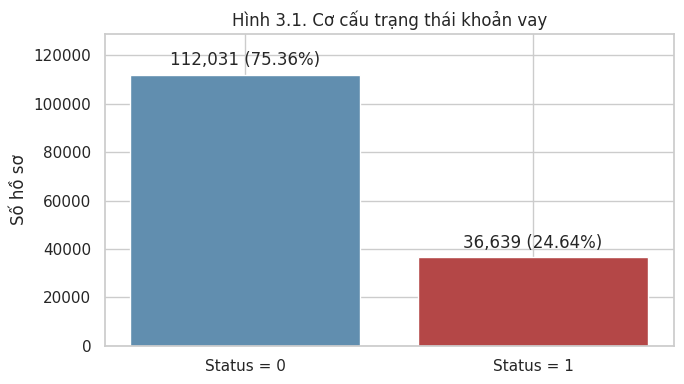

In [229]:
#3.1.1. Phân phối biến mục tiêu
# Sử dụng toàn bộ hồ sơ vì biến status không thiếu.
status_n = eda["status"].value_counts().reindex([0, 1], fill_value=0)
status_pct = status_n.div(len(eda)).mul(100)
display(pd.DataFrame({"Số hồ sơ": status_n, "Tỷ lệ (%)": status_pct.round(2)}))

# Hình 3.1: tần suất và tỷ lệ status.
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Status = 0", "Status = 1"], status_n, color=["#618eaf", "#b44747"])
ax.bar_label(bars, [f"{n:,} ({p:.2f}%)" for n, p in zip(status_n, status_pct)], padding=4)
ax.set_ylim(0, status_n.max() * 1.15)
ax.set_ylabel("Số hồ sơ")
ax.set_title("Hình 3.1. Cơ cấu trạng thái khoản vay")
plt.tight_layout()


In [230]:
#3.1.2. Đặc điểm quy mô khoản vay
# Bảng thống kê trên dữ liệu quan sát được của từng biến.
display(bang_mo_ta(["loan_amount", "property_value", "term"]))
print(f"Hồ sơ kỳ hạn 360 tháng: {eda['term'].eq(360).sum():,} "
      f"({eda['term'].eq(360).mean():.2%})")

,N hợp lệ,Thiếu (%),Trung bình,Trung vị,Q1,Q3,P99,Tối đa
loan_amount,148670,0.000,"331,117.740","296,500.000","196,500.000","436,500.000","856,500.000","3,576,500.000"
property_value,133572,10.160,"497,893.470","418,000.000","268,000.000","628,000.000","1,808,000.000","16,508,000.000"
term,148670,0.000,335.140,360.000,360.000,360.000,360.000,360.000


Hồ sơ kỳ hạn 360 tháng: 121,726 (81.88%)


In [231]:
#3.1.3. Đặc điểm tài chính người vay
# Bảng N hợp lệ và tỷ lệ thiếu bắt buộc đi cùng các thống kê.
display(bang_mo_ta(["income", "credit_score", "ltv", "dtir1"]))
print("Số hồ sơ income = 0:", f"{eda['income'].eq(0).sum():,}")
print("Số hồ sơ LTV > 1.000%:", f"{eda['ltv'].gt(1000).sum():,}")


,N hợp lệ,Thiếu (%),Trung bình,Trung vị,Q1,Q3,P99,Tối đa
income,139520,6.150,"6,957.340","5,760.000","3,720.000","8,520.000","26,640.000","578,580.000"
credit_score,148670,0.000,699.790,699.000,599.000,800.000,897.000,900.000
ltv,133572,10.160,72.750,75.140,60.470,86.180,102.760,"7,831.250"
dtir1,124549,16.220,37.730,39.000,31.000,45.000,60.000,61.000


Số hồ sơ income = 0: 1,260
Số hồ sơ LTV > 1.000%: 6


In [232]:
#3.1.4. Đặc điểm phân loại
# Bảng cơ cấu ba biến phân loại theo tổng số 148.670 hồ sơ.
cat_rows = []
for label, col in [("Loại vay", "loan_type"),
                   ("Mục đích vay", "loan_purpose"),
                   ("Giới tính/đồng vay", "gender")]:
    for group, n in eda[col].value_counts(dropna=False).items():
        cat_rows.append([label, str(group), n, 100 * n / len(eda)])
cat_table = pd.DataFrame(cat_rows, columns=["Biến", "Nhóm", "Số hồ sơ", "Tỷ lệ (%)"])
display(cat_table.round(2))

,Biến,Nhóm,Số hồ sơ,Tỷ lệ (%)
0,Loại vay,type1,113173,76.120
1,Loại vay,type2,20762,13.970
2,Loại vay,type3,14735,9.910
3,Mục đích vay,p3,55934,37.620
4,Mục đích vay,p4,54799,36.860
5,Mục đích vay,p1,34529,23.230
6,Mục đích vay,p2,3274,2.200
7,Mục đích vay,unknown,134,0.090
8,Giới tính/đồng vay,male,42346,28.480
9,Giới tính/đồng vay,joint,41399,27.850


Độ lệch (skewness) toàn bộ: 1.67


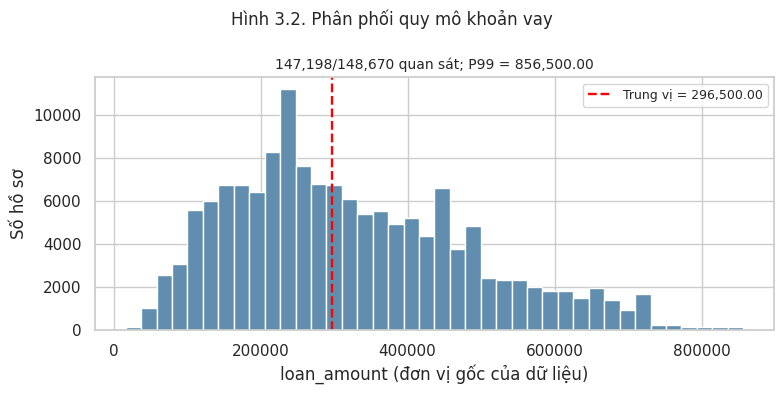

In [233]:
#3.2. Phân tích phân phối từng biến (Univariate Analysis)
#3.2.1. Phân phối loan_amount
# Hình 3.2: Chỉ phóng vùng đến P99, không loại hồ sơ khỏi dữ liệu.
fig, ax = plt.subplots(figsize=(8, 4))
ve_hist(ax, "loan_amount", bins=40, p99=True)
ax.set_xlabel("loan_amount (đơn vị gốc của dữ liệu)")
fig.suptitle("Hình 3.2. Phân phối quy mô khoản vay", fontsize=12)
plt.tight_layout()
print(f"Độ lệch (skewness) toàn bộ: {eda['loan_amount'].skew():.2f}")

Độ lệch (skewness) trên N hợp lệ: 17.31


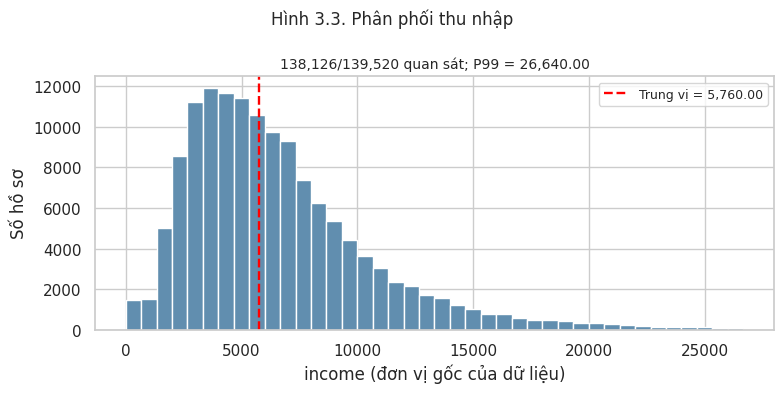

In [234]:
#3.2.2. Phân phối income
# Hình 3.3: Bỏ NaN riêng khi vẽ; không đổi các khoản income = 0.
fig, ax = plt.subplots(figsize=(8, 4))
ve_hist(ax, "income", bins=40, p99=True)
ax.set_xlabel("income (đơn vị gốc của dữ liệu)")
fig.suptitle("Hình 3.3. Phân phối thu nhập", fontsize=12)
plt.tight_layout()
print(f"Độ lệch (skewness) trên N hợp lệ: {eda['income'].skew():.2f}")

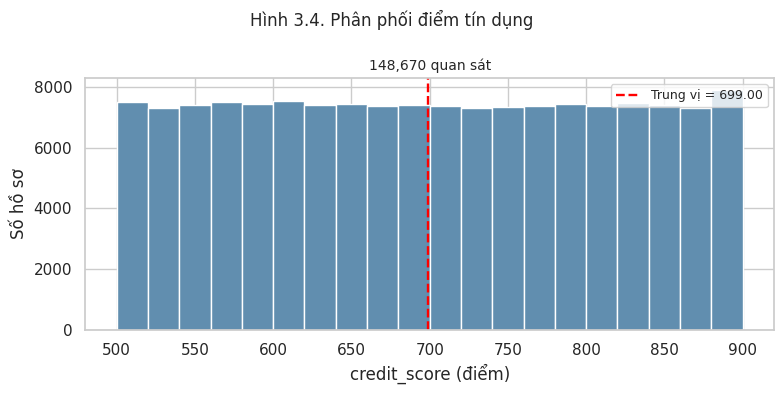

Tần suất theo nhóm điểm đã tạo ở Chương 2:


,Số hồ sơ
credit_score_band,
500–599,37190
600–699,37200
700–799,36811
800–900,37469


In [235]:
#3.2.3. Phân phối credit_score
# Hình 3.4: Hiển thị toàn bộ dải 500–900, không cắt ngưỡng P99.
fig, ax = plt.subplots(figsize=(8, 4))
ve_hist(ax, "credit_score", bins=20)
ax.set_xlabel("credit_score (điểm)")
fig.suptitle("Hình 3.4. Phân phối điểm tín dụng", fontsize=12)
plt.tight_layout()
plt.show()
print("Tần suất theo nhóm điểm đã tạo ở Chương 2:")
display(eda['credit_score_band'].value_counts(sort=False).to_frame("Số hồ sơ"))

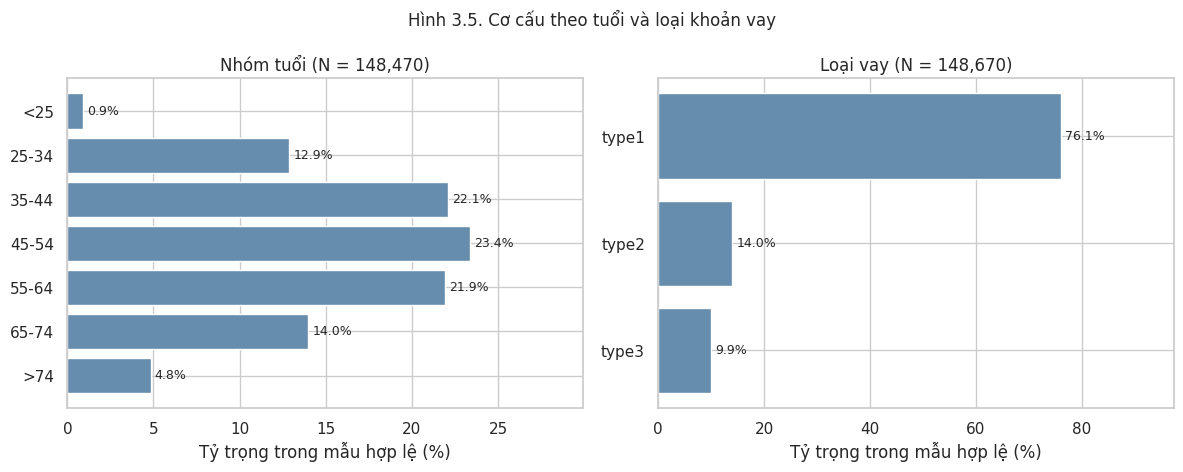

Hồ sơ age=unknown (không đưa vào biểu đồ tuổi): 200


In [236]:
#3.2.4. Phân phối theo nhóm tuổi và loại khoản vay
# Hình 3.5: age=unknown không phải nhóm tuổi nên loại khỏi mẫu số biểu đồ tuổi.
age_order = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
age_n = eda.loc[eda['age'].isin(age_order), 'age'].value_counts().reindex(age_order, fill_value=0)
loan_n = eda['loan_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, counts, title in [
    (axes[0], age_n, f"Nhóm tuổi (N = {age_n.sum():,})"),
    (axes[1], loan_n, f"Loại vay (N = {loan_n.sum():,})")]:
    percentage = counts.div(counts.sum()).mul(100)
    bars = ax.barh(counts.index, percentage, color='#668dad')
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_xlim(0, percentage.max() * 1.28)
    ax.invert_yaxis()
    ax.set_xlabel("Tỷ trọng trong mẫu hợp lệ (%)")
    ax.set_title(title)
fig.suptitle("Hình 3.5. Cơ cấu theo tuổi và loại khoản vay", fontsize=12)
plt.tight_layout()
plt.show()
print("Hồ sơ age=unknown (không đưa vào biểu đồ tuổi):", eda['age'].eq('unknown').sum())

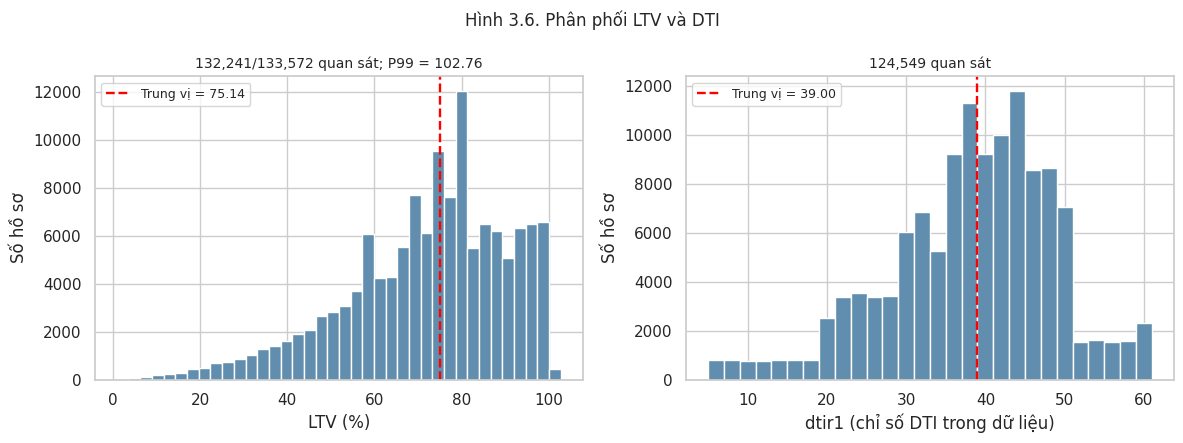

LTV > 1.000% (giữ nguyên): 6 hồ sơ
Tỷ lệ thiếu LTV / DTI: 10.16% / 16.22%


In [237]:
#3.2.5. Phân phối các chỉ số ltv và dtir1
# Hình 3.6: LTV chỉ phóng đến P99 do có 6 giá trị > 1.000%; DTI hiện toàn bộ.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ve_hist(axes[0], 'ltv', bins=38, p99=True)
ve_hist(axes[1], 'dtir1', bins=28)
axes[0].set_xlabel("LTV (%)")
axes[1].set_xlabel("dtir1 (chỉ số DTI trong dữ liệu)")
fig.suptitle("Hình 3.6. Phân phối LTV và DTI", fontsize=12)
plt.tight_layout()
plt.show()
print(f"LTV > 1.000% (giữ nguyên): {eda['ltv'].gt(1000).sum():,} hồ sơ")
print("Tỷ lệ thiếu LTV / DTI:",
      f"{eda['ltv'].isna().mean():.2%} / {eda['dtir1'].isna().mean():.2%}")

In [238]:
#3.3. Phân tích chất lượng dữ liệu theo trạng thái vỡ nợ
#3.3.1. So sánh Missing Values giữa hai nhóm Status
# 7 biến số còn NaN; 2 biến phân loại thiếu gốc đã được gán nhãn 'unknown' ở Chương 2.
missing_vars = ['interest_rate_spread', 'rate_of_interest', 'upfront_charges',
                'property_value', 'ltv', 'dtir1', 'income']
assert all(eda[c].isna().any() for c in missing_vars)

missing_flags = eda[missing_vars].isna().copy()
for col in ['age', 'submission_of_application']:
    # Phân biệt thiếu gốc đã chuyển thành 'unknown' với NaN còn tồn tại.
    assert eda[col].eq('unknown').sum() == df_raw[col].isna().sum()
    missing_flags[f'{col} (unknown)'] = eda[col].eq('unknown')

miss0 = missing_flags.loc[eda.status.eq(0)].mean() * 100
miss1 = missing_flags.loc[eda.status.eq(1)].mean() * 100
bang_33 = pd.DataFrame({'Thiếu | status=0 (%)': miss0,
                        'Thiếu | status=1 (%)': miss1,
                        'Chênh lệch (đpt; 1−0)': miss1 - miss0})
print('Bảng 3.3. Missing theo status (7 biến còn NaN, 2 biến thiếu gốc đã gán unknown):')
display(bang_33.round(2))
#Lưu ý: age và submission_of_application không còn là NaN sau làm sạch;' hai dòng cuối phản ánh thiếu dữ liệu gốc, không phải nhóm tuổi/kênh nộp thực.'

Bảng 3.3. Missing theo status (7 biến còn NaN, 2 biến thiếu gốc đã gán unknown):


,Thiếu | status=0 (%),Thiếu | status=1 (%),Chênh lệch (đpt; 1−0)
interest_rate_spread,0.000,100.000,100.000
rate_of_interest,0.000,99.450,99.450
upfront_charges,2.820,99.580,96.770
property_value,0.000,41.200,41.200
ltv,0.000,41.200,41.200
dtir1,6.970,44.520,37.540
income,7.060,3.380,-3.680
age (unknown),0.000,0.550,0.550
submission_of_application (unknown),0.000,0.550,0.550


In [239]:
#3.3.2. Phân tích sự khác biệt về mẫu quan sát
# Không xóa dữ liệu: mỗi mask chỉ dùng tính chỉ số trên một tập con.
mau_day_du = {
    'Toàn bộ dữ liệu': pd.Series(True, index=eda.index),
    'Có income': eda['income'].notna(),
    'Có ltv': eda['ltv'].notna(),
    'Có dtir1': eda['dtir1'].notna(),
    'Có đủ income + ltv + dtir1': eda[['income', 'ltv', 'dtir1']].notna().all(axis=1)
}
nen_chung = eda.status.mean() * 100
bang_mau = pd.DataFrame([
    {'Mẫu': name, 'N giữ lại': int(mask.sum()), 'Tỷ lệ giữ lại (%)': 100 * mask.mean(),
     'Số status=1': int(eda.loc[mask, 'status'].sum()),
     'Status=1 trong mẫu (%)': 100 * eda.loc[mask, 'status'].mean(),
     'Lệch so với toàn bộ (đpt)': 100 * eda.loc[mask, 'status'].mean() - nen_chung}
    for name, mask in mau_day_du.items()
]).set_index('Mẫu')
display(bang_mau.round(2))

,N giữ lại,Tỷ lệ giữ lại (%),Số status=1,Status=1 trong mẫu (%),Lệch so với toàn bộ (đpt)
Mẫu,,,,,
Toàn bộ dữ liệu,148670,100.000,36639,24.640,0.000
Có income,139520,93.850,35400,25.370,0.730
Có ltv,133572,89.840,21543,16.130,-8.520
Có dtir1,124549,83.780,20329,16.320,-8.320
Có đủ income + ltv + dtir1,124437,83.700,20319,16.330,-8.320


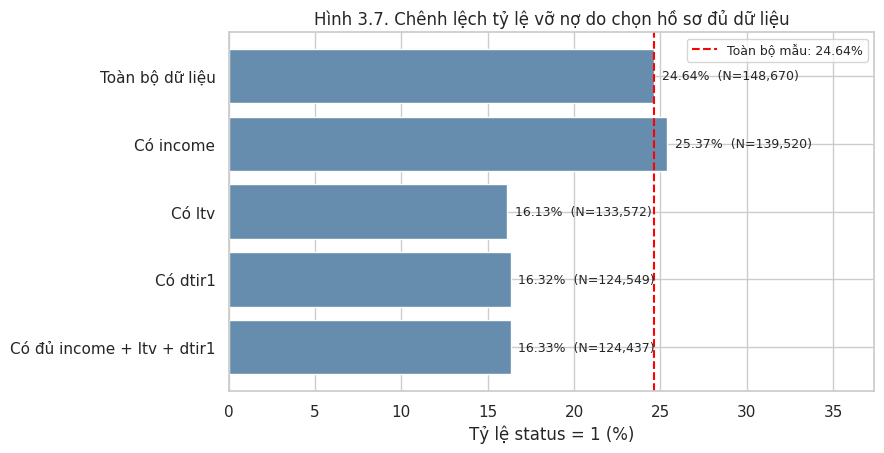

Tuổi không xác định (age=unknown): 200 | status=1: 200
Bảng 3.4a. Tình trạng thiếu LTV theo credit_type:


,LTV có dữ liệu,LTV thiếu,Tỷ lệ thiếu LTV (%)
credit_type,,,
cib,48151,1,0.000
crif,43900,1,0.000
equi,202,15096,98.680
exp,41319,0,0.000


Trong 15,098 hồ sơ thiếu LTV, có 15,096 hồ sơ loại equi.


In [240]:
# Hình 3.7: chỉ so tỷ lệ trên các mẫu quan sát khác nhau, kèm N giữ lại.
fig, ax = plt.subplots(figsize=(9, 4.7))
vals = bang_mau['Status=1 trong mẫu (%)']
bars = ax.barh(vals.index, vals, color='#668dad')
ax.axvline(nen_chung, color='red', ls='--', lw=1.5,
           label=f'Toàn bộ mẫu: {nen_chung:.2f}%')
for bar, pct, n in zip(bars, vals, bang_mau['N giữ lại']):
    ax.text(pct + .45, bar.get_y() + bar.get_height()/2,
            f'{pct:.2f}%  (N={n:,})', va='center', fontsize=9)
ax.set_xlim(0, vals.max() + 12)
ax.invert_yaxis()
ax.set_xlabel('Tỷ lệ status = 1 (%)')
ax.set_title('Hình 3.7. Chênh lệch tỷ lệ vỡ nợ do chọn hồ sơ đủ dữ liệu')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print('Tuổi không xác định (age=unknown):', int(eda.age.eq('unknown').sum()),
      '| status=1:', int(eda.loc[eda.age.eq('unknown'), 'status'].sum()))
# Đối chiếu nguồn gốc thiếu LTV/property_value theo credit_type (không sửa dữ liệu).
nguon_thieu = pd.crosstab(eda['credit_type'], eda['ltv'].isna()).reindex(columns=[False, True], fill_value=0)
nguon_thieu.columns = ['LTV có dữ liệu', 'LTV thiếu']
nguon_thieu['Tỷ lệ thiếu LTV (%)'] = (100 * nguon_thieu['LTV thiếu'] / nguon_thieu.sum(axis=1))
print('Bảng 3.4a. Tình trạng thiếu LTV theo credit_type:')
display(nguon_thieu.round(2))
print(f"Trong {int(eda.ltv.isna().sum()):,} hồ sơ thiếu LTV, "
      f"có {int((eda.credit_type.eq('equi') & eda.ltv.isna()).sum()):,} hồ sơ loại equi.")


In [241]:
# Đối chiếu cơ cấu mẫu: sự thiếu LTV gần như loại nhóm EQUI khỏi phân tích LTV.
equi = eda['credit_type'].eq('equi')
co_ltv = eda['ltv'].notna()
bang_doi_chieu_equi = pd.DataFrame([
    {'Mẫu': ten, 'N': int(mask.sum()), 'Số status=1': int(eda.loc[mask, 'status'].sum()),
     'Tỷ lệ status=1 (%)': 100 * eda.loc[mask, 'status'].mean()}
    for ten, mask in [('Toàn bộ dữ liệu', pd.Series(True, index=eda.index)),
                      ('Không gồm EQUI', ~equi),
                      ('Có dữ liệu LTV', co_ltv)]
]).set_index('Mẫu')
print('Bảng 3.4b. Đối chiếu tỷ lệ status=1 và cơ cấu EQUI khi chọn mẫu:')
display(bang_doi_chieu_equi.round(2))
print(f"EQUI: {equi.sum():,} hồ sơ, {int(eda.loc[equi, 'status'].sum()):,} status=1; "
      f"chiếm {100 * (equi & eda.status.eq(1)).sum() / eda.status.sum():.2f}% "
      'tổng số status=1.')
print(f"EQUI chiếm {(equi & ~co_ltv).sum():,}/{(~co_ltv).sum():,} "
      f"({100*(equi & ~co_ltv).sum()/(~co_ltv).sum():.2f}%) hồ sơ thiếu LTV.")
print('Nhận xét: Tỷ lệ status=1 trong mẫu có LTV gần tỷ lệ khi bỏ EQUI; '
      'sự giảm so với toàn mẫu chủ yếu phản ánh thay đổi cơ cấu credit_type, '
      'không chứng minh LTV là nguyên nhân làm thay đổi tình trạng vỡ nợ.')

Bảng 3.4b. Đối chiếu tỷ lệ status=1 và cơ cấu EQUI khi chọn mẫu:


,N,Số status=1,Tỷ lệ status=1 (%)
Mẫu,,,
Toàn bộ dữ liệu,148670,36639,24.640
Không gồm EQUI,133372,21342,16.000
Có dữ liệu LTV,133572,21543,16.130


EQUI: 15,298 hồ sơ, 15,297 status=1; chiếm 41.75% tổng số status=1.
EQUI chiếm 15,096/15,098 (99.99%) hồ sơ thiếu LTV.
Nhận xét: Tỷ lệ status=1 trong mẫu có LTV gần tỷ lệ khi bỏ EQUI; sự giảm so với toàn mẫu chủ yếu phản ánh thay đổi cơ cấu credit_type, không chứng minh LTV là nguyên nhân làm thay đổi tình trạng vỡ nợ.


In [242]:
#3.4. Phân tích mối quan hệ giữa các biến và tình trạng vỡ nợ
# Hàm chung cho 3.4: tính tỷ lệ status=1 và khoảng Wilson 95% theo nhóm.
# Thông tin thiếu đã được phân tích ở 3.3; nhóm thiếu không bị coi bằng 0.
def bang_ty_le(nhom, thu_tu):
    tmp = pd.DataFrame({'nhom': nhom, 'status': eda['status']}).dropna(subset=['nhom'])
    g = tmp.groupby('nhom', observed=True)['status'].agg(N='size', So_1='sum').reindex(thu_tu)
    g = g.dropna().astype(int)
    p, n, z = g['So_1'] / g['N'], g['N'], 1.96
    mid = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    g['Tỷ lệ (%)'] = 100*p
    g['CI thấp (%)'] = 100*(mid - half)
    g['CI cao (%)'] = 100*(mid + half)
    return g.rename(columns={'So_1': 'Status=1'})

# Vẽ chung các tỷ lệ nhóm, sai số Wilson 95% và đường nền của mẫu hợp lệ.
def ve_ty_le(ax, bang, nen, tieu_de):
    y = np.arange(len(bang))
    val = bang['Tỷ lệ (%)'].to_numpy()
    ax.barh(y, val, color='#618eaf', height=.68)
    lo = val - bang['CI thấp (%)'].to_numpy()
    hi = bang['CI cao (%)'].to_numpy() - val
    ax.errorbar(val, y, xerr=[lo, hi], fmt='none', color='#2c3f50', capsize=2, lw=1)
    ax.axvline(nen, color='red', ls='--', lw=1.3,
               label=f'Nền mẫu hợp lệ: {nen:.2f}%')
    ax.set_yticks(y, bang.index.astype(str))
    ax.invert_yaxis()
    ax.set_xlim(0, max(40, bang['CI cao (%)'].max() + 7) if bang['CI cao (%)'].max() < 95 else 105)
    ax.set_xlabel('Status = 1 (%) — khoảng Wilson 95%')
    ax.set_title(tieu_de, fontsize=11)
    ax.legend(fontsize=8, loc='lower right')

,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
<25,1337,387,28.950,26.580,31.430
25-34,19142,4248,22.190,21.610,22.790
35-44,32818,7309,22.270,21.820,22.720
45-54,34720,8349,24.050,23.600,24.500
55-64,32534,8422,25.890,25.410,26.370
65-74,20744,5571,26.860,26.260,27.460
>74,7175,2153,30.010,28.960,31.080


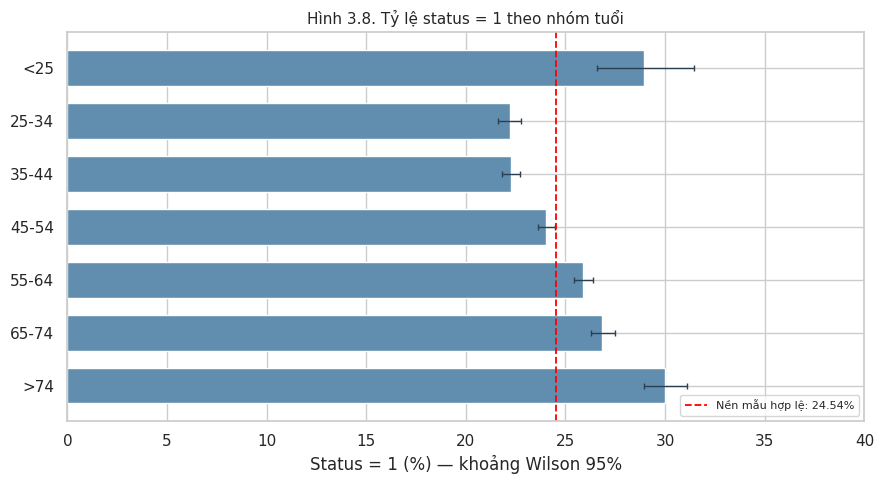

In [243]:
#3.4.1. Tỷ lệ vỡ nợ theo nhóm tuổi
tuoi_hop_le = eda['age'].isin(age_order)
bang_tuoi = bang_ty_le(eda.loc[tuoi_hop_le, 'age'], age_order)
display(bang_tuoi.round(2))
fig, ax = plt.subplots(figsize=(9, 5))
ve_ty_le(ax, bang_tuoi, 100*eda.loc[tuoi_hop_le, 'status'].mean(),
          'Hình 3.8. Tỷ lệ status = 1 theo nhóm tuổi')
plt.tight_layout(); plt.show()

Các mốc tứ phân vị thu nhập dương: ['60', '3,780', '5,760', '8,580', '578,580']
Mẫu income hợp lệ: 139520 | thiếu: 9150


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
Income = 0,1260,1252,99.370,98.750,99.680
Q1,35075,11568,32.980,32.490,33.470
Q2,34293,8382,24.440,23.990,24.900
Q3,34791,7303,20.990,20.570,21.420
Q4,34101,6895,20.220,19.800,20.650


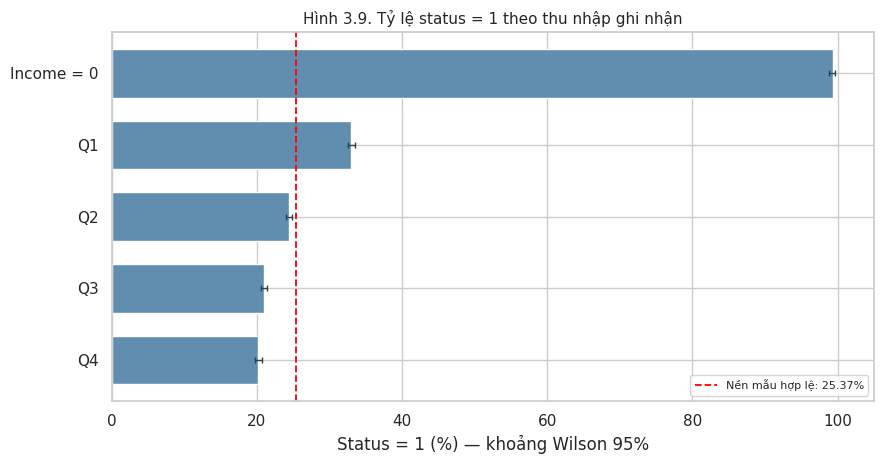

In [244]:
#3.4.2. Tỷ lệ vỡ nợ theo thu nhập
# Q1–Q4 chỉ trên income > 0; giữ nhóm income = 0 riêng, không gộp với Q1.
thu_nhap = pd.Series(pd.NA, index=eda.index, dtype='string')
co_thu_nhap = eda['income'].gt(0)
thu_nhap.loc[co_thu_nhap] = pd.qcut(eda.loc[co_thu_nhap, 'income'], 4,
                                    labels=['Q1', 'Q2', 'Q3', 'Q4']).astype('string')
thu_nhap.loc[eda['income'].eq(0)] = 'Income = 0'
thu_tu_income = ['Income = 0', 'Q1', 'Q2', 'Q3', 'Q4']
bang_income = bang_ty_le(thu_nhap, thu_tu_income)
nguong_income = pd.qcut(eda.loc[co_thu_nhap, 'income'], 4, retbins=True)[1]
print('Các mốc tứ phân vị thu nhập dương:', [f'{x:,.0f}' for x in nguong_income])
print('Mẫu income hợp lệ:', int(eda.income.notna().sum()), '| thiếu:', int(eda.income.isna().sum()))
display(bang_income.round(2))
fig, ax = plt.subplots(figsize=(9, 4.8))
ve_ty_le(ax, bang_income, 100*eda.loc[eda.income.notna(), 'status'].mean(),
          'Hình 3.9. Tỷ lệ status = 1 theo thu nhập ghi nhận')
plt.tight_layout(); plt.show()

,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
500–599,37190,9160,24.630,24.200,25.070
600–699,37200,9108,24.480,24.050,24.920
700–799,36811,8940,24.290,23.850,24.730
800–900,37469,9431,25.170,24.730,25.610


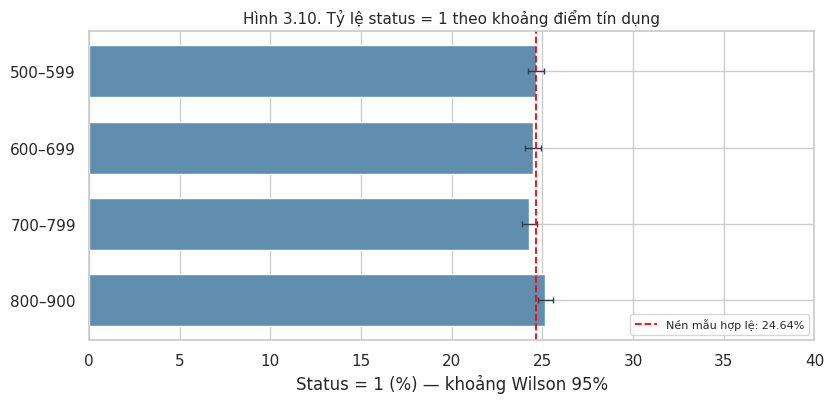

In [245]:
#3.4.3. Điểm tín dụng và tình trạng vỡ nợ
# Credit score đủ dữ liệu; so sánh tỷ lệ status=1 ở bốn khoảng điểm
score_order = ['500–599', '600–699', '700–799', '800–900']
bang_score = bang_ty_le(eda['credit_score_band'], score_order)
display(bang_score.round(2))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ve_ty_le(ax, bang_score, 100*eda.status.mean(),
          'Hình 3.10. Tỷ lệ status = 1 theo khoảng điểm tín dụng')
plt.tight_layout(); plt.show()

Các mốc phân vị loan_amount: ['16,500', '176,500', '256,500', '346,500', '476,500', '3,576,500']


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
Q1,31920,9737,30.500,30.000,31.010
Q2,29910,7503,25.090,24.600,25.580
Q3,28557,6633,23.230,22.740,23.720
Q4,30419,6499,21.360,20.910,21.830
Q5,27864,6267,22.490,22.000,22.990


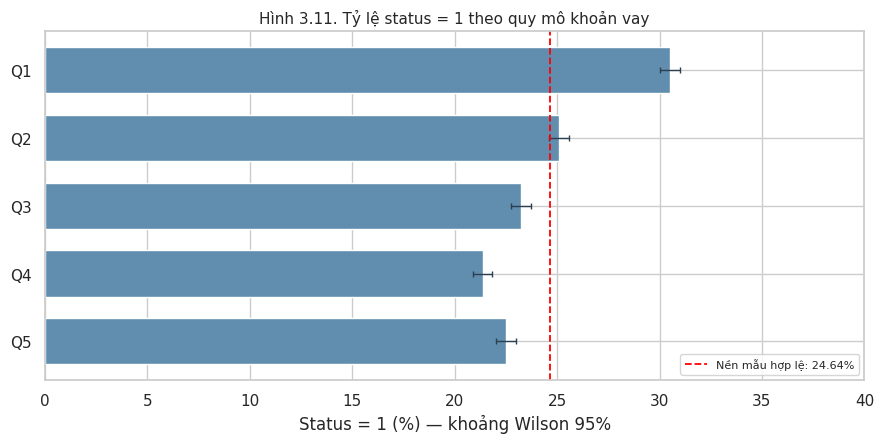

In [246]:
#3.4.4. Quy mô khoản vay và tình trạng vỡ nợ
# loan_amount đủ dữ liệu: chia năm phân vị
nhom_vay = pd.qcut(eda['loan_amount'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
nguong_vay = pd.qcut(eda['loan_amount'], 5, retbins=True)[1]
print('Các mốc phân vị loan_amount:', [f'{x:,.0f}' for x in nguong_vay])
bang_vay = bang_ty_le(nhom_vay, ['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
display(bang_vay.round(2))
fig, ax = plt.subplots(figsize=(9, 4.6))
ve_ty_le(ax, bang_vay, 100*eda.status.mean(),
          'Hình 3.11. Tỷ lệ status = 1 theo quy mô khoản vay')
plt.tight_layout(); plt.show()

,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
≤60%,32565,4534,13.920,13.550,14.300
60–80%,49895,6456,12.940,12.650,13.240
80–90%,26153,4822,18.440,17.970,18.910
90–100%,23160,4560,19.690,19.180,20.210
>100%,1799,1171,65.090,62.860,67.260


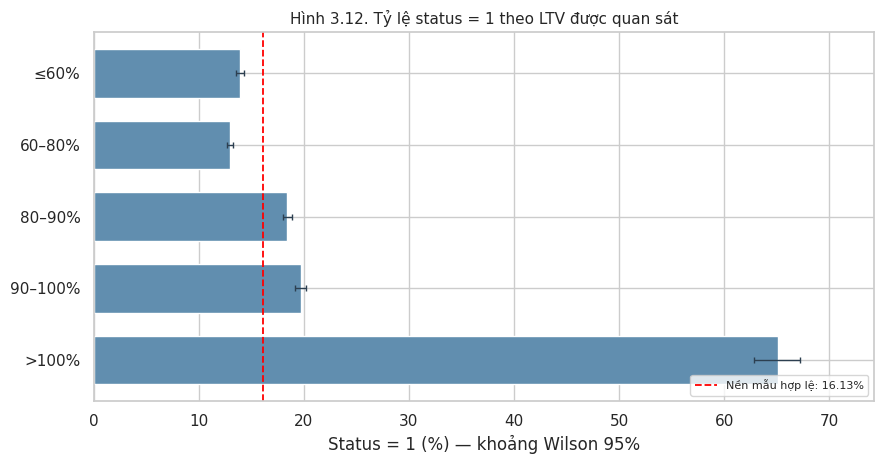

Nhóm 100% < LTV ≤ 1000%: N=1,793, status=1=65.25%; LTV >1000%: 6 hồ sơ.


In [247]:
#3.4.5. Tỷ lệ LTV và tình trạng vỡ nợ
# LTV là tỷ lệ phần trăm theo dữ liệu; loại NaN khỏi mẫu số nhưng giữ mọi giá trị cực trị.
nhom_ltv = pd.cut(eda['ltv'], [-np.inf, 60, 80, 90, 100, np.inf],
                  labels=['≤60%', '60–80%', '80–90%', '90–100%', '>100%'])
ltv_order = ['≤60%', '60–80%', '80–90%', '90–100%', '>100%']
bang_ltv = bang_ty_le(nhom_ltv, ltv_order)
display(bang_ltv.round(2))
fig, ax = plt.subplots(figsize=(9, 4.8))
ve_ty_le(ax, bang_ltv, 100*eda.loc[eda.ltv.notna(), 'status'].mean(),
          'Hình 3.12. Tỷ lệ status = 1 theo LTV được quan sát')
plt.tight_layout(); plt.show()

# Kiểm tra độ nhạy riêng nhóm >100% nếu không tính sáu giá trị cực trị >1000%.
ltv_100_1000 = eda['ltv'].gt(100) & eda['ltv'].le(1000)
print(f'Nhóm 100% < LTV ≤ 1000%: N={ltv_100_1000.sum():,}, '
      f'status=1={eda.loc[ltv_100_1000, "status"].mean():.2%}; '
      f'LTV >1000%: {eda.ltv.gt(1000).sum():,} hồ sơ.')

,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
≤30,27970,4364,15.600,15.180,16.030
30–40,41861,5109,12.200,11.890,12.520
40–50,46079,7164,15.550,15.220,15.880
>50,8639,3692,42.740,41.700,43.780


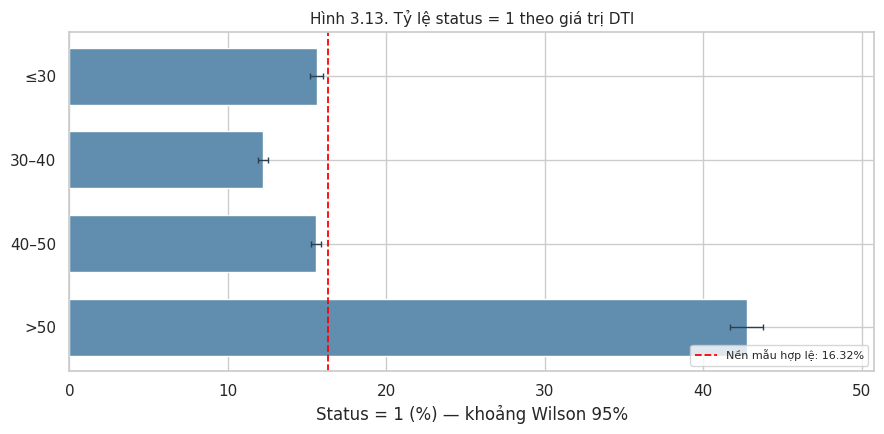

In [248]:
#3.4.6. DTI và tình trạng vỡ nợ
# So sánh phân tầng DTI trên đúng tập có dtir1 quan sát được.
nhom_dti = pd.cut(eda['dtir1'], [-np.inf, 30, 40, 50, np.inf],
                  labels=['≤30', '30–40', '40–50', '>50'])
dti_order = ['≤30', '30–40', '40–50', '>50']
bang_dti = bang_ty_le(nhom_dti, dti_order)
display(bang_dti.round(2))
fig, ax = plt.subplots(figsize=(9, 4.5))
ve_ty_le(ax, bang_dti, 100*eda.loc[eda.dtir1.notna(), 'status'].mean(),
          'Hình 3.13. Tỷ lệ status = 1 theo giá trị DTI')
plt.tight_layout(); plt.show()

Loại khoản vay:


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
type1,113173,25775,22.770,22.530,23.020
type2,20762,7172,34.540,33.900,35.190
type3,14735,3692,25.060,24.360,25.760


Mục đích vay:


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
p1,34529,8935,25.880,25.420,26.340
p2,3274,1083,33.080,31.490,34.710
p3,55934,13996,25.020,24.670,25.380
p4,54799,12590,22.970,22.620,23.330
unknown,134,35,26.120,19.420,34.150


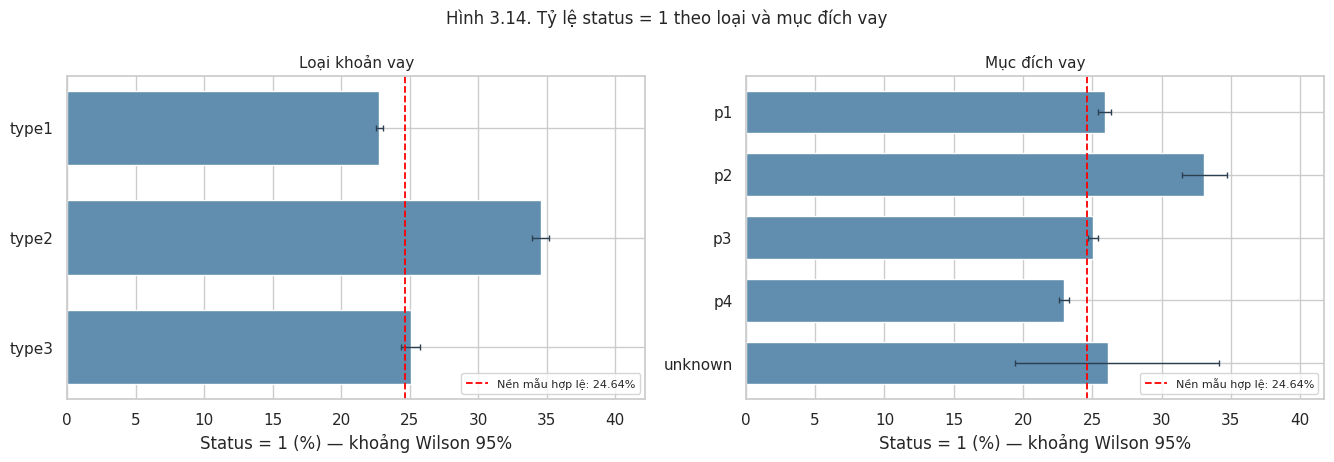

In [249]:
#3.4.7. Loại khoản vay và mục đích vay
# Bảng: Loại khoản vay và mục đích vay
loan_type_order = ['type1', 'type2', 'type3']
purpose_order = ['p1', 'p2', 'p3', 'p4', 'unknown']
bang_loai_vay = bang_ty_le(eda['loan_type'], loan_type_order)
bang_muc_dich = bang_ty_le(eda['loan_purpose'], purpose_order)
print('Loại khoản vay:'); display(bang_loai_vay.round(2))
print('Mục đích vay:'); display(bang_muc_dich.round(2))

# Hình 3.14: Tỷ lệ status = 1 theo loại và mục đích vay
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))
ve_ty_le(axes[0], bang_loai_vay, 100*eda.status.mean(), 'Loại khoản vay')
ve_ty_le(axes[1], bang_muc_dich, 100*eda.status.mean(), 'Mục đích vay')
fig.suptitle('Hình 3.14. Tỷ lệ status = 1 theo loại và mục đích vay', fontsize=12)
plt.tight_layout(); plt.show()

,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
not_lpsm,145286,34011,23.410,23.190,23.630
lpsm,3384,2628,77.660,76.230,79.030


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
not_neg,133420,29860,22.380,22.160,22.600
neg_amm,15129,6747,44.600,43.810,45.390
unknown,121,32,26.450,19.400,34.940


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
cib,74392,13713,18.430,18.160,18.710
exp,74278,22926,30.870,30.530,31.200


,N,Status=1,Tỷ lệ (%),CI thấp (%),CI cao (%)
nhom,,,,,
to_inst,95814,27213,28.400,28.120,28.690
not_inst,52656,9226,17.520,17.200,17.850


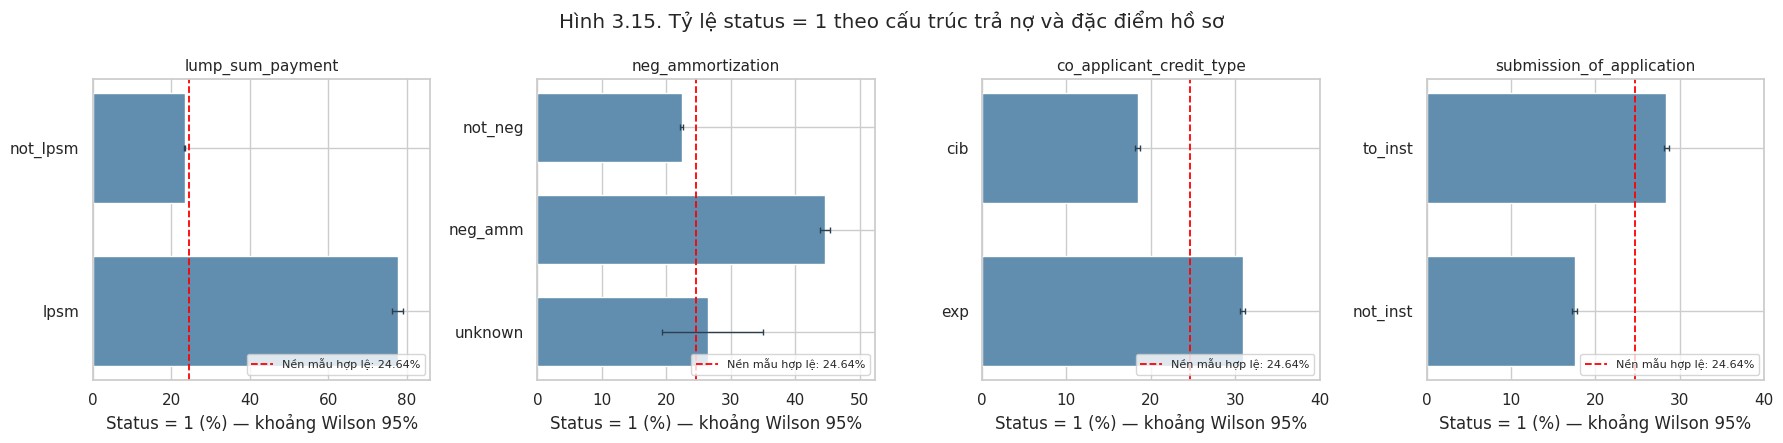

In [250]:
# 3.4.8. Cấu trúc trả nợ
# Hình 3.15: tỷ lệ status=1 theo cấu trúc trả nợ và đặc điểm hồ sơ
cac_bien = [('lump_sum_payment', ['not_lpsm','lpsm']),
            ('neg_ammortization', ['not_neg','neg_amm','unknown']),
            ('co_applicant_credit_type', ['cib','exp']),
            ('submission_of_application', ['to_inst','not_inst'])]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (col, order) in zip(axes, cac_bien):
    sub = eda[eda[col].isin(order)]
    bang = bang_ty_le(sub[col], order)
    display(bang.round(2))
    ve_ty_le(ax, bang, 100*eda.status.mean(), col)
fig.suptitle('Hình 3.15. Tỷ lệ status = 1 theo cấu trúc trả nợ và đặc điểm hồ sơ')
plt.tight_layout(); plt.show()

In [251]:

# 3.5. Kiểm định giả thuyết nghiên cứu
from scipy.stats import chi2_contingency, mannwhitneyu, false_discovery_control
from itertools import combinations

# 1. Kiểm định Chi-square và tính Cramér's V
def kiem_chi2(ma, ten, nhom):
    tmp = pd.DataFrame({'nhom': nhom, 'status': eda['status']}).dropna()
    bang = pd.crosstab(tmp['nhom'], tmp['status']).reindex(columns=[0, 1], fill_value=0)

    chi2, p, do_tu_do, expected = chi2_contingency(bang, correction=False)
    assert expected.min() >= 5, f'Ô tần số kỳ vọng nhỏ ở {ma}; cần thay kiểm định.'

    v = np.sqrt(chi2 / (len(tmp) * min(bang.shape[0]-1, bang.shape[1]-1)))
    return [ma, ten, len(tmp), f'χ²({do_tu_do}) = {chi2:,.1f}', p, f'V = {v:.3f}', v]


# 2. Kiểm định Mann–Whitney U và tính Cliff's delta
def kiem_mann_whitney(ma, ten, bien):
    mau_1 = eda.loc[eda['status'].eq(1), bien].dropna()
    mau_0 = eda.loc[eda['status'].eq(0), bien].dropna()

    u, p = mannwhitneyu(mau_1, mau_0, alternative='two-sided', method='asymptotic')
    delta = 2*u / (len(mau_1)*len(mau_0)) - 1

    return [ma, ten, len(mau_1)+len(mau_0), f'U = {u:,.0f}', p,
            f'Cliff δ = {delta:+.3f}', delta]


# 3. Thực hiện 7 kiểm định
kiem_dinh = [
    kiem_chi2('H1a', 'Nhóm tuổi × status', eda['age'].where(eda['age'].isin(age_order))),
    kiem_chi2('H1b', 'Loại vay × status', eda['loan_type']),
    kiem_mann_whitney('H2', 'Income theo status', 'income'),
    kiem_mann_whitney('H3', 'Credit score theo status', 'credit_score'),
    kiem_chi2('H4', '5 phân vị loan_amount × status', nhom_vay),
    kiem_chi2('H5a', 'Nhóm LTV × status', nhom_ltv),
    kiem_chi2('H5b', 'Nhóm DTI × status', nhom_dti)
]

ket_qua_35 = pd.DataFrame(kiem_dinh, columns=[
    'Mã', 'Giả thuyết', 'N', 'Thống kê', 'p_thuc', 'Hiệu ứng', 'Hiệu ứng số'
])

# 4. Hiệu chỉnh FDR bằng Benjamini–Hochberg
ket_qua_35['q_fdr'] = false_discovery_control(
    ket_qua_35['p_thuc'].to_numpy(), method='bh'
)

# 5. Trình bày bảng kết quả
def dinh_dang_p(p):
    return '<1e-300' if p == 0 else (f'{p:.2e}' if p < 1e-3 else f'{p:.4f}')

bang_35 = ket_qua_35[['Mã', 'Giả thuyết', 'N', 'Thống kê', 'Hiệu ứng']].copy()

for hien_thi, cot in [('p', 'p_thuc'), ('q (FDR)', 'q_fdr')]:
    bang_35[hien_thi] = ket_qua_35[cot].map(dinh_dang_p)

bang_35['Kết luận (α=5%)'] = np.where(
    ket_qua_35['q_fdr'] < .05,
    'Có bằng chứng liên hệ', 'Chưa đủ bằng chứng'
)

print('Bảng 3.5. Kết quả 7 phép kiểm định (p=0 do tràn số chỉ biểu thị là p rất nhỏ):')
display(bang_35)

print('Đối chiếu trung vị:')
display(eda.groupby('status')[['income', 'credit_score']].median().rename(
    index={0: 'Status = 0', 1: 'Status = 1'}))


Bảng 3.5. Kết quả 7 phép kiểm định (p=0 do tràn số chỉ biểu thị là p rất nhỏ):


,Mã,Giả thuyết,N,Thống kê,Hiệu ứng,p,q (FDR),Kết luận (α=5%)
0,H1a,Nhóm tuổi × status,148470,χ²(6) = 374.5,V = 0.050,8.44e-78,9.85e-78,Có bằng chứng liên hệ
1,H1b,Loại vay × status,148670,"χ²(2) = 1,310.0",V = 0.094,3.52e-285,6.16e-285,Có bằng chứng liên hệ
2,H2,Income theo status,139520,"U = 1,502,807,176",Cliff δ = -0.185,<1e-300,<1e-300,Có bằng chứng liên hệ
3,H3,Credit score theo status,148670,"U = 2,063,311,078",Cliff δ = +0.005,0.1243,0.1243,Chưa đủ bằng chứng
4,H4,5 phân vị loan_amount × status,148670,χ²(4) = 870.0,V = 0.076,5.38e-187,7.53e-187,Có bằng chứng liên hệ
5,H5a,Nhóm LTV × status,133572,"χ²(4) = 4,000.8",V = 0.173,<1e-300,<1e-300,Có bằng chứng liên hệ
6,H5b,Nhóm DTI × status,124549,"χ²(3) = 4,963.7",V = 0.200,<1e-300,<1e-300,Có bằng chứng liên hệ


Đối chiếu trung vị:


,income,credit_score
status,,
Status = 0,"6,000.000",699.000
Status = 1,"4,860.000",700.000


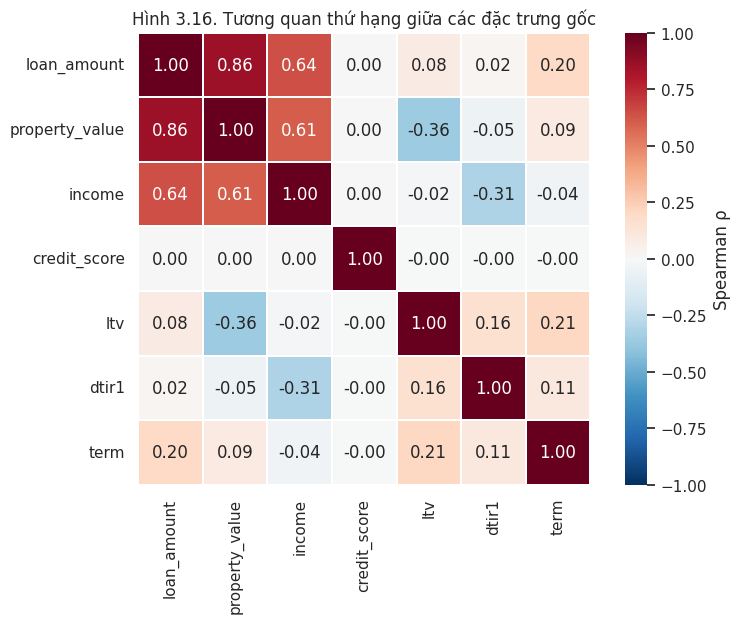

Số cặp quan sát hợp lệ (N) theo từng ô:


,loan_amount,property_value,income,credit_score,ltv,dtir1,term
loan_amount,148670,133572,139520,148670,133572,124549,148670
property_value,133572,133572,124437,133572,133572,124547,133572
income,139520,124437,139520,139520,124437,124439,139520
credit_score,148670,133572,139520,148670,133572,124549,148670
ltv,133572,133572,124437,133572,133572,124547,133572
dtir1,124549,124547,124439,124549,124547,124549,124549
term,148670,133572,139520,148670,133572,124549,148670


In [252]:
#3.6. Phân tích mối quan hệ đa biến
#3.6.1. Ma trận tương quan
# Hình 3.15 — Tương quan Spearman giữa các biến gốc (không đưa status vào ma trận).
bien_tuong_quan = ['loan_amount', 'property_value', 'income', 'credit_score',
                  'ltv', 'dtir1', 'term']
ma_tran_spearman = eda[bien_tuong_quan].corr(method='spearman')
ma_n = eda[bien_tuong_quan].notna().astype(int).T.dot(
    eda[bien_tuong_quan].notna().astype(int))

fig, ax = plt.subplots(figsize=(8.4, 6.4))
sns.heatmap(ma_tran_spearman, ax=ax, annot=True, fmt='.2f',
            vmin=-1, vmax=1, center=0, cmap='RdBu_r', square=True,
            linewidths=.35, cbar_kws={'label': 'Spearman ρ'})
ax.set_title('Hình 3.16. Tương quan thứ hạng giữa các đặc trưng gốc')
plt.tight_layout(); plt.show()
print('Số cặp quan sát hợp lệ (N) theo từng ô:')
display(ma_n)

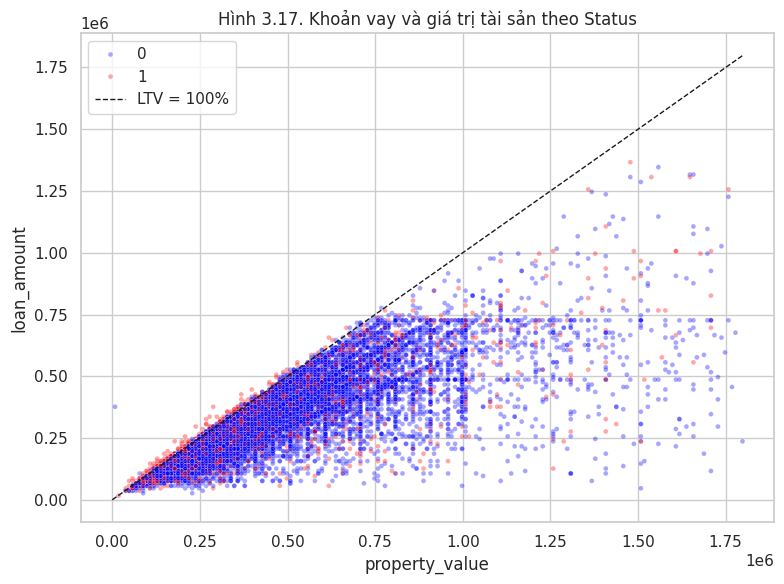

In [253]:
#Biểu đồ Scatter plot: quan hệ loan_amount và property_value
d = eda[['loan_amount','property_value','status']].dropna()
d = d[d.property_value < d.property_value.quantile(.99)]   # chỉ để hiển thị
d = d.sample(15000, random_state=123)
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data=d, x='property_value', y='loan_amount', hue='status',
                alpha=.35, s=12, palette={0:'blue',1:'red'}, ax=ax)
lim = d.property_value.max()
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='LTV = 100%')
ax.legend(); ax.set_title('Hình 3.17. Khoản vay và giá trị tài sản theo Status')
plt.tight_layout(); plt.show()

In [254]:
#3.6.2. Phát hiện mối liên hệ mạnh giữa các đặc trưng
# Liệt kê duy nhất các cặp đạt |ρ| >= 0,30, kèm N quan sát của từng cặp
cap_manh = pd.DataFrame([
    {'Cặp biến': f'{a} ↔ {b}', 'Spearman ρ': ma_tran_spearman.loc[a, b],
     'N cặp hợp lệ': int(ma_n.loc[a, b])}
    for a, b in combinations(bien_tuong_quan, 2)
    if abs(ma_tran_spearman.loc[a, b]) >= .30
]).sort_values('Spearman ρ', key=lambda s: s.abs(), ascending=False)
print('Bảng 3.6. Các cặp có |ρ| ≥ 0,30:')
display(cap_manh.round(3))

Bảng 3.6. Các cặp có |ρ| ≥ 0,30:


,Cặp biến,Spearman ρ,N cặp hợp lệ
0,loan_amount ↔ property_value,0.857,133572
1,loan_amount ↔ income,0.642,139520
2,property_value ↔ income,0.606,124437
3,property_value ↔ ltv,-0.365,133572
4,income ↔ dtir1,-0.307,124439


In [255]:
#3.6.3. Liên hệ biến phân loại với status (Cramér's V trên từng mẫu hợp lệ).
# Loại 'unknown' ở age và submission_of_application để không nhầm thiếu gốc với nhóm thực.
rows_v = []
for col in all_categorical:
    if col not in eda.columns:
        continue
    tmp = eda[[col, 'status']].dropna()
    if col in ['age', 'submission_of_application']:
        tmp = tmp.loc[tmp[col].ne('unknown')]
    tab = pd.crosstab(tmp[col], tmp['status']).reindex(columns=[0, 1], fill_value=0)
    if min(tab.shape) < 2:
        continue  # Không thể tính liên hệ khi chỉ có một nhóm.
    chi2 = chi2_contingency(tab, correction=False)[0]
    v = np.sqrt(chi2 / (len(tmp) * min(tab.shape[0]-1, tab.shape[1]-1)))
    rows_v.append({'Biến phân loại': col, 'N hợp lệ': len(tmp), 'Cramér V': v})

bang_v_phan_loai = pd.DataFrame(rows_v).sort_values(
    'Cramér V', ascending=False).reset_index(drop=True)
print('Bảng 3.6b. Liên hệ với status: N tính riêng cho từng biến;'
      ' loại unknown của tuổi và hình thức nộp hồ sơ:')
display(bang_v_phan_loai.round(3))
# Đối chiếu mục 3.5: cùng định nghĩa nhóm tuổi -> cùng kích thước hiệu ứng.
v_tuoi = bang_v_phan_loai.loc[bang_v_phan_loai['Biến phân loại'].eq('age'), 'Cramér V'].iloc[0]
v_h1a = ket_qua_35.loc[ket_qua_35['Mã'].eq('H1a'), 'Hiệu ứng số'].iloc[0]
assert np.isclose(v_tuoi, v_h1a), 'Cramér V tuổi ở 3.5 và 3.6.2 không khớp.'

Bảng 3.6b. Liên hệ với status: N tính riêng cho từng biến; loại unknown của tuổi và hình thức nộp hồ sơ:


,Biến phân loại,N hợp lệ,Cramér V
0,credit_type,148670,0.592
1,lump_sum_payment,148670,0.188
2,neg_ammortization,148670,0.156
3,co_applicant_credit_type,148670,0.144
4,submission_of_application,148470,0.121
5,loan_type,148670,0.094
6,gender,148670,0.084
7,loan_limit,148670,0.054
8,region,148670,0.051
9,age,148470,0.050


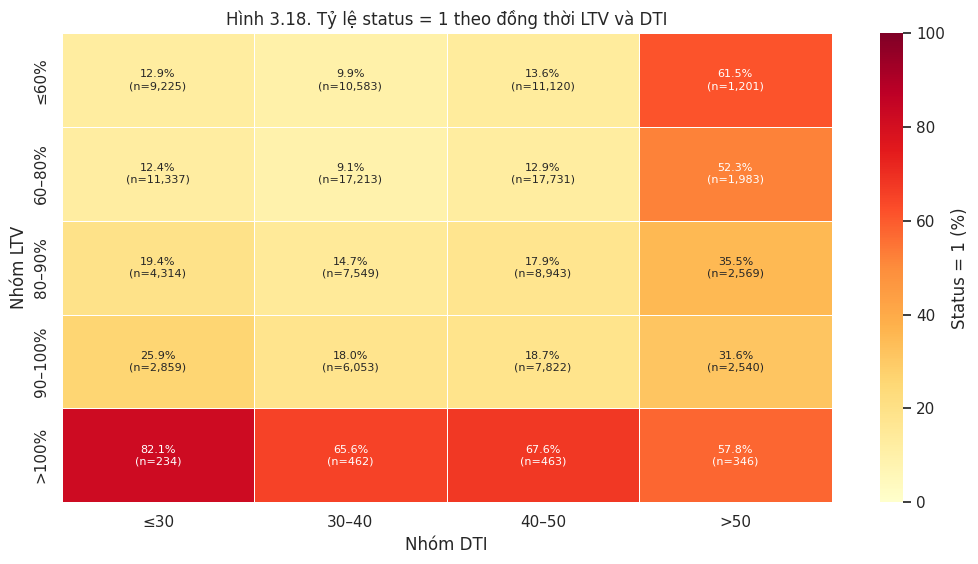

Mẫu có cả LTV và DTI: 124,547 hồ sơ; tỷ lệ status=1: 16.32%; nhóm nhỏ nhất: 234 hồ sơ.


In [256]:
#3.6.4. Phân tích phân khúc kết hợp
# Hình 3.16 — Phân khúc kết hợp LTV × DTI trên cùng một tập hồ sơ đủ hai chỉ số.
phan_khuc = pd.DataFrame({'LTV': nhom_ltv, 'DTI': nhom_dti,
                         'status': eda['status']}).dropna()
grid_36 = phan_khuc.groupby(['LTV', 'DTI'], observed=True)['status'].agg(
    N='size', So_1='sum', Ty_le='mean')
grid_pct = grid_36['Ty_le'].unstack('DTI').reindex(index=ltv_order, columns=dti_order) * 100
grid_n = grid_36['N'].unstack('DTI').reindex(index=ltv_order, columns=dti_order)
# Chỉ hiện ô đủ 100 hồ sơ; ô ít hơn không đủ ổn định để so sánh trực quan.
nhan = grid_pct.copy().astype(object)
for i in range(len(nhan.index)):
    for j in range(len(nhan.columns)):
        n = grid_n.iloc[i, j]
        nhan.iloc[i, j] = f'{grid_pct.iloc[i, j]:.1f}%\n(n={int(n):,})' if pd.notna(n) and n >= 100 else 'N < 100'
fig, ax = plt.subplots(figsize=(10.5, 5.8))
sns.heatmap(grid_pct.where(grid_n >= 100), annot=nhan, fmt='', ax=ax,
            cmap='YlOrRd', vmin=0, vmax=100, linewidths=.4,
            annot_kws={'fontsize': 8}, cbar_kws={'label': 'Status = 1 (%)'})
ax.set_title('Hình 3.18. Tỷ lệ status = 1 theo đồng thời LTV và DTI')
ax.set_xlabel('Nhóm DTI'); ax.set_ylabel('Nhóm LTV')
plt.tight_layout(); plt.show()
print(f'Mẫu có cả LTV và DTI: {len(phan_khuc):,} hồ sơ; '
      f'tỷ lệ status=1: {100*phan_khuc.status.mean():.2f}%; '
      f'nhóm nhỏ nhất: {int(grid_n.min().min()):,} hồ sơ.')
assert int(grid_n.sum().sum()) == len(phan_khuc)

In [257]:
#3.6.5. Kiểm tra độ nhạy của kết quả
# Bảng 3.7 — Sensitivity analysis: luôn đối chiếu hai nhóm trên cùng mẫu.
mau_chung = eda[['ltv', 'dtir1']].notna().all(axis=1)
mau_duong = mau_chung & eda['income'].gt(0)

cac_kich_ban = [
    ('LTV', 'Có LTV', eda['ltv'].notna(), 'ltv', 100),
    ('LTV', 'Có LTV, loại 6 cực trị >1.000%', eda['ltv'].notna() & eda['ltv'].le(1000), 'ltv', 100),
    ('LTV', 'Có cả LTV và DTI', mau_chung, 'ltv', 100),
    ('LTV', 'Cả hai, income dương', mau_duong, 'ltv', 100),
    ('DTI', 'Có DTI', eda['dtir1'].notna(), 'dtir1', 50),
    ('DTI', 'Có cả LTV và DTI', mau_chung, 'dtir1', 50),
    ('DTI', 'Cả hai, income dương', mau_duong, 'dtir1', 50),
]
dong_do_nhay = []
for ten, kich_ban, mask, bien, nguong in cac_kich_ban:
    nhom_cao = mask & eda[bien].gt(nguong)
    nhom_thap = mask & eda[bien].le(nguong)
    p_cao = 100*eda.loc[nhom_cao, 'status'].mean()
    p_thap = 100*eda.loc[nhom_thap, 'status'].mean()
    dong_do_nhay.append({'Biến': ten, 'Kịch bản': kich_ban,
                         'N mẫu': int(mask.sum()), 'N nhóm cao': int(nhom_cao.sum()),
                         'Tỷ lệ nhóm cao (%)': p_cao, 'Tỷ lệ còn lại (%)': p_thap,
                         'Chênh lệch (đpt)': p_cao-p_thap})
bang_nhay_36 = pd.DataFrame(dong_do_nhay)
display(bang_nhay_36.round(2))
print('Sáu hồ sơ có LTV >1.000%:', int(eda.ltv.gt(1000).sum()),
      '| số hồ sơ trong mẫu có cả LTV và DTI:', int((mau_chung & eda.ltv.gt(1000)).sum()))

# Đối chiếu hiệu ứng thu nhập khi không xét giá trị 0 và khi chỉ còn mẫu đủ LTV/DTI.
thu_nhap_nhay = []
for ten, mask in [('Income ghi nhận', eda.income.notna()),
                  ('Income dương', eda.income.gt(0)),
                  ('Income dương + đủ LTV/DTI', mau_duong)]:
    s1 = eda.loc[mask & eda.status.eq(1), 'income']
    s0 = eda.loc[mask & eda.status.eq(0), 'income']
    u, _ = mannwhitneyu(s1, s0, method='asymptotic')
    thu_nhap_nhay.append({'Mẫu': ten, 'N': int(mask.sum()),
                           'Median status=0': s0.median(), 'Median status=1': s1.median(),
                           'Cliff δ': 2*u/(len(s1)*len(s0)) - 1})
print('Độ nhạy của liên hệ thu nhập với status:')
display(pd.DataFrame(thu_nhap_nhay).round(3))

,Biến,Kịch bản,N mẫu,N nhóm cao,Tỷ lệ nhóm cao (%),Tỷ lệ còn lại (%),Chênh lệch (đpt)
0,LTV,Có LTV,133572,1799,65.090,15.460,49.630
1,LTV,"Có LTV, loại 6 cực trị >1.000%",133566,1793,65.250,15.460,49.790
2,LTV,Có cả LTV và DTI,124547,1505,66.980,15.700,51.270
3,LTV,"Cả hai, income dương",124089,1499,66.910,15.480,51.430
4,DTI,Có DTI,124549,8639,42.740,14.350,28.380
5,DTI,Có cả LTV và DTI,124547,8639,42.740,14.350,28.380
6,DTI,"Cả hai, income dương",124089,8635,42.730,14.110,28.620


Sáu hồ sơ có LTV >1.000%: 6 | số hồ sơ trong mẫu có cả LTV và DTI: 0
Độ nhạy của liên hệ thu nhập với status:


,Mẫu,N,Median status=0,Median status=1,Cliff δ
0,Income ghi nhận,139520,"6,000.000","4,860.000",-0.185
1,Income dương,138260,"6,000.000","5,040.000",-0.155
2,Income dương + đủ LTV/DTI,124089,"6,000.000","4,680.000",-0.213
